# U-net

## Imports

In [1]:
# In[4]:

import os, json, time, hashlib, shutil, math
from pathlib import Path
from itertools import product
import random  # NEW

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, classification_report

# --------------------------
# Reproducible seeding
# --------------------------
SEED = 42  # or any integer you like

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Make cuDNN deterministic (slightly slower but reproducible)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Global seed set to: {SEED}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Global seed set to: 42
device: cuda
GPU: NVIDIA GeForce RTX 2060


## Basic Data Loading

In [2]:
from pathlib import Path
import numpy as np

DATASET_NAME = "ECG5000"
# DATASET_NAME = "NonInvasiveFetalECGThorax1"
# DATASET_NAME = "NonInvasiveFetalECGThorax2"

# Robust path resolution (handles running notebook from different cwd)
HERE = Path().resolve()
DATA_ROOT = HERE / "Data"
if not DATA_ROOT.exists():
    # fallback: search one level up (common if notebook is in subfolder)
    if (HERE.parent / "Data").exists():
        DATA_ROOT = HERE.parent / "Data"

DATA_DIR = DATA_ROOT / DATASET_NAME
assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}"

train_path = DATA_DIR / f"{DATASET_NAME}_TRAIN.ts"
test_path  = DATA_DIR / f"{DATASET_NAME}_TEST.ts"
assert train_path.exists(), f"Missing: {train_path}"
assert test_path.exists(), f"Missing: {test_path}"

print("Using dataset:", DATASET_NAME)
print("Train file:", train_path)
print("Test file :", test_path)

def load_ucr_ts(ts_path: Path):
    """
    Minimal UCR/UEA .ts loader for univariate classification datasets.
    Returns: X (N, L) float32, y_raw (N,) as original labels (strings)
    """
    X, y = [], []
    in_data = False

    with ts_path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            low = line.lower()

            # header control
            if low.startswith("@data"):
                in_data = True
                continue
            if not in_data:
                continue

            # data lines:
            # format typically: series_values:label
            # where series_values are comma-separated floats
            if ":" not in line:
                continue

            series_part, label_part = line.rsplit(":", 1)
            label = label_part.strip()
            series_str = series_part.strip()

            # Handle optional parentheses/whitespace
            # Values may be like "0.1,0.2,..." (univariate)
            vals = [v for v in series_str.split(",") if v != ""]
            vals = np.array(vals, dtype=np.float32)

            X.append(vals)
            y.append(label)

    X = np.stack(X, axis=0).astype(np.float32)
    y = np.array(y)

    return X, y

# Load raw labels
X_train_full, y_train_raw = load_ucr_ts(train_path)
X_test, y_test_raw        = load_ucr_ts(test_path)

# Map labels -> 0..K-1 consistently using TRAIN classes
unique_labels = sorted(np.unique(y_train_raw).tolist())
label_to_idx = {lab: i for i, lab in enumerate(unique_labels)}

y_train_full = np.array([label_to_idx[lab] for lab in y_train_raw], dtype=np.int64)
y_test       = np.array([label_to_idx.get(lab, -1) for lab in y_test_raw], dtype=np.int64)

# Sanity check: test labels must all exist in training label set
assert (y_test >= 0).all(), "Found test labels not present in training labels."

classes = unique_labels  # for plotting
num_classes = len(classes)
seq_len = X_train_full.shape[1]

print("Train shape:", X_train_full.shape, "Test shape:", X_test.shape)
print("Classes:", classes, "| num_classes:", num_classes, "| seq_len:", seq_len)


# X_train_full, y_train_full, X_test, y_test already loaded above

from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
import numpy as np

# 1) Combine TRAIN + TEST into one pool
X_all = np.concatenate([X_train_full, X_test], axis=0)
y_all = np.concatenate([y_train_full, y_test], axis=0)

# 2) 60/20/20 split via two-stage stratified splitting
#    Stage A: 20% test
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

#    Stage B: from remaining 80%, take 25% as val => 0.25 * 0.80 = 0.20 overall
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp,
    test_size=0.25,
    random_state=42,
    stratify=y_tmp
)

print("Split sizes:",
      "train", len(X_train),
      "val", len(X_val),
      "test", len(X_test))



Using dataset: ECG5000
Train file: E:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TRAIN.ts
Test file : E:\Repos\U-net_cikk\Data\ECG5000\ECG5000_TEST.ts
Train shape: (500, 140) Test shape: (4500, 140)
Classes: ['1', '2', '3', '4', '5'] | num_classes: 5 | seq_len: 140
Split sizes: train 3000 val 1000 test 1000


## Normalize per sample

In [3]:

def zscore_per_sample(X, eps=1e-8):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    return (X - mu) / (sd + eps)

X_train = zscore_per_sample(X_train)
X_val   = zscore_per_sample(X_val)
X_test  = zscore_per_sample(X_test)


## Pytorch Datalset/Dataloader

In [4]:
class ECGDataset(Dataset):
    def __init__(self, X, y, augment=False, max_shift=0):
        """
        X: np.array, shape (N, L)
        y: np.array, shape (N,)
        augment: if True, apply random time-shift
        max_shift: maximum absolute shift (in samples). 0 disables shifting.
        """
        self.X = torch.from_numpy(X).unsqueeze(1)  # (N, 1, L)
        self.y = torch.from_numpy(y).long()
        self.augment = augment
        self.max_shift = int(max_shift)

    def __len__(self):
        return len(self.X)

    def _random_shift(self, x):
        """
        x: tensor of shape (C, L)
        Returns: shifted tensor with zero-padding (no wrap-around).
        """
        if self.max_shift <= 0:
            return x

        # Sample shift uniformly in [-max_shift, max_shift]
        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x

        L = x.shape[-1]

        if shift > 0:
            # Shift to the right: new values at the left are zero
            pad = torch.zeros_like(x[..., :shift])
            x_shifted = torch.cat([pad, x[..., :-shift]], dim=-1)
        else:
            # Shift to the left: new values at the right are zero
            s = -shift
            pad = torch.zeros_like(x[..., :s])
            x_shifted = torch.cat([x[..., s:], pad], dim=-1)

        return x_shifted

    def __getitem__(self, i):
        x = self.X[i]
        y = self.y[i]

        if self.augment and self.max_shift > 0:
            x = self._random_shift(x)

        return x, y


# ---- Augmentation settings ----
AUG_TIME_SHIFT = False   # set to True for the augmented experiment
MAX_SHIFT = 5            # in samples, e.g. ±5; tune as desired

train_ds = ECGDataset(
    X_train, y_train,
    augment=AUG_TIME_SHIFT,
    max_shift=MAX_SHIFT,
)
val_ds   = ECGDataset(
    X_val,   y_val,
    augment=False,
    max_shift=0,
)
test_ds  = ECGDataset(
    X_test,  y_test,
    augment=False,
    max_shift=0,
)

# Optional: deterministic shuffling if you have SEED defined
# g = torch.Generator()
# g.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True,
    drop_last=True,
    # generator=g,
)

val_loader = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
)


## Spectrogram dataset (STFT)

In [5]:
import torch
from torch.utils.data import Dataset

class SpectrogramDataset(Dataset):
    """
    Converts 1D signal (L,) to log-magnitude STFT spectrogram (1, F, T).
    Optional per-item cache to avoid recomputing STFT each epoch.
    """
    def __init__(self, X, y, n_fft=128, hop_length=32, win_length=None,
                 log_eps=1e-6, augment=False, max_shift=0, cache=True):
        self.X = torch.from_numpy(X).float()  # (N, L)
        self.y = torch.from_numpy(y).long()
        self.n_fft = int(n_fft)
        self.hop_length = int(hop_length)
        self.win_length = int(win_length) if win_length is not None else self.n_fft
        self.log_eps = float(log_eps)

        # reuse your existing shift augmentation idea
        self.augment = augment
        self.max_shift = int(max_shift)

        self.cache = bool(cache)
        self._cache = {}  # idx -> spec tensor (1,F,T)

        self.window = torch.hann_window(self.win_length)

    def __len__(self):
        return len(self.X)

    def _random_shift_1d(self, x_1d):
        if self.max_shift <= 0:
            return x_1d
        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x_1d
        L = x_1d.shape[0]
        if shift > 0:
            pad = torch.zeros(shift, dtype=x_1d.dtype)
            return torch.cat([pad, x_1d[:L-shift]], dim=0)
        else:
            s = -shift
            pad = torch.zeros(s, dtype=x_1d.dtype)
            return torch.cat([x_1d[s:], pad], dim=0)

    def _make_spec(self, x_1d):
        # x_1d: (L,)
        # stft -> (F, T) complex
        stft = torch.stft(
            x_1d,
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window.to(x_1d.device),
            center=True,
            return_complex=True,
        )
        mag = stft.abs()  # (F,T)
        logmag = torch.log(mag + self.log_eps)
        # add channel dim -> (1,F,T)
        return logmag.unsqueeze(0)

    def __getitem__(self, i):
        if self.cache and i in self._cache:
            return self._cache[i].clone(), self.y[i]

        x = self.X[i]  # (L,)
        if self.augment and self.max_shift > 0:
            x = self._random_shift_1d(x)

        spec = self._make_spec(x)

        if self.cache:
            self._cache[i] = spec.detach().cpu()

        return spec, self.y[i]


## Train/Eval utils

In [6]:
import numpy as np
import torch
import torch.nn as nn

# If you already import tqdm elsewhere, keep that.
import tqdm.auto as tq


def train_one_epoch(model, loader, opt, criterion, epoch=0, verbose=False):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    it = loader
    if verbose:
        it = tq.tqdm(loader, desc=f"Train {epoch+1}", leave=False)

    for xb, yb in it:
        xb, yb = xb.to(device), yb.to(device)

        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        opt.step()

        bs = xb.size(0)
        total_loss += float(loss.item()) * bs
        correct += int((logits.argmax(1) == yb).sum().item())
        n += int(bs)

        if verbose:
            it.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss / max(n, 1), correct / max(n, 1)


@torch.no_grad()
def eval_model(model, loader, criterion, epoch=0, verbose=False):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_y = [], []

    it = loader
    if verbose:
        it = tq.tqdm(loader, desc=f"Eval  {epoch+1}", leave=False)

    for xb, yb in it:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += float(loss.item()) * bs
        preds = logits.argmax(1)

        correct += int((preds == yb).sum().item())
        n += int(bs)

        all_preds.append(preds.detach().cpu().numpy())
        all_y.append(yb.detach().cpu().numpy())

        if verbose:
            it.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss / max(n, 1), correct / max(n, 1), np.concatenate(all_y), np.concatenate(all_preds)


def fit(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=0.0, verbose=False):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = -1.0
    best_state = None
    history = []

    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, criterion, epoch=epoch, verbose=verbose)
        val_loss, val_acc, _, _ = eval_model(model, val_loader, criterion, epoch=epoch, verbose=verbose)

        history.append({
            "epoch": epoch + 1,
            "train_loss": float(tr_loss),
            "train_acc": float(tr_acc),
            "val_loss": float(val_loss),
            "val_acc": float(val_acc),
        })

        if val_acc > best_val_acc:
            best_val_acc = float(val_acc)
            # Store best weights on CPU (prevents GPU memory growth and helps GC)
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        # IMPORTANT: Only print per-epoch if verbose=True
        if verbose:
            print(
                f"Epoch {epoch+1:03d}/{epochs:03d} | "
                f"train acc={tr_acc:.4f} loss={tr_loss:.4f} | "
                f"val acc={val_acc:.4f} loss={val_loss:.4f}"
            )

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


## Grad-CAM utils

In [7]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def __call__(self, x, class_idx=None):
        """
        x: (1, 1, L)
        returns cam: (L,)
        """
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()

        score = logits[:, class_idx]
        score.backward()

        # activations: (1, C, L') gradients: (1, C, L')
        A = self.activations
        dA = self.gradients

        # global-average pool gradients over time to get weights per channel
        weights = dA.mean(dim=-1, keepdim=True)  # (1, C, 1)

        cam = (weights * A).sum(dim=1)  # (1, L')
        cam = F.relu(cam)

        # upsample cam to input length
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-1], mode="linear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.softmax(1).detach().cpu().numpy()

def show_gradcam_1d(model, dataset, idx, class_names=None, target_layer=None):
    model.eval()
    x, y = dataset[idx]
    x_in = x.unsqueeze(0).to(device)

    # pick default layer if not provided
    if target_layer is None:
        # try to use last conv in decoder (dec1) if exists
        target_layer = getattr(model, "dec1", None)
        if target_layer is not None and hasattr(target_layer, "net"):
            # last Conv1d in that block
            target_layer = target_layer.net[3]
        else:
            # fallback: last Conv1d we can find
            convs = [m for m in model.modules() if isinstance(m, torch.nn.Conv1d)]
            target_layer = convs[-1]

    cam_engine = GradCAM1D(model, target_layer)
    cam, pred_idx, probs = cam_engine(x_in)

    sig = x.squeeze().numpy()
    L = sig.shape[0]

    plt.figure(figsize=(10,3))
    plt.plot(sig, label="ECG")
    plt.fill_between(np.arange(L), sig.min(), sig.max(), where=cam>0,
                     alpha=0.3, step="mid")
    plt.title(
        f"Grad-CAM 1D | true={y.item()} pred={pred_idx} "
        + (f"({class_names[pred_idx]})" if class_names else "")
    )
    plt.legend()
    plt.show()

    print("Class probs:", probs[0])


import torch
import torch.nn.functional as F

def match_length(a, b):
    """
    Make tensors a and b have the same last-dimension length by center-cropping the longer one.
    a, b: (N, C, L)
    Returns: (a_matched, b_matched)
    """
    La = a.shape[-1]
    Lb = b.shape[-1]
    if La == Lb:
        return a, b

    if La > Lb:
        diff = La - Lb
        left = diff // 2
        right = diff - left
        a = a[..., left:La-right]
    else:
        diff = Lb - La
        left = diff // 2
        right = diff - left
        b = b[..., left:Lb-right]

    return a, b


import os, gc, time
import torch

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:
    _PROC = None

def mem_report(tag=""):
    # CPU RSS
    rss_gb = None
    if _PROC is not None:
        rss_gb = _PROC.memory_info().rss / (1024**3)

    # GPU
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / (1024**2)
        reserv = torch.cuda.memory_reserved() / (1024**2)
        maxalloc = torch.cuda.max_memory_allocated() / (1024**2)
        msg_gpu = f"GPU alloc={alloc:.0f}MB reserved={reserv:.0f}MB max_alloc={maxalloc:.0f}MB"
    else:
        msg_gpu = "GPU n/a"

    msg_cpu = f"CPU RSS={rss_gb:.2f}GB" if rss_gb is not None else "CPU RSS n/a"
    print(f"[mem] {tag} | {msg_cpu} | {msg_gpu}")


## Model 1: Compact 1D U-net

In [8]:
class TemporalConvHead1D(nn.Module):
    """
    Dense temporal classification head.

    The head first produces class evidence at each temporal location and then
    pools that evidence into sample-level logits. This keeps the current
    ECG5000 training loop unchanged while making the head compatible with
    long/continuous signals where local abnormal morphology matters.
    """
    def __init__(self, in_channels, num_classes, dropout=0.0, hidden=None, pool="lse", lse_tau=1.0, topk_frac=0.25):
        super().__init__()
        hidden = hidden or max(num_classes, in_channels // 2)
        self.pool = pool
        self.lse_tau = float(lse_tau)
        self.topk_frac = float(topk_frac)
        self.evidence = nn.Sequential(
            nn.Conv1d(in_channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, num_classes, kernel_size=1),
        )

    def pool_logits(self, temporal_logits):
        if self.pool == "mean":
            return temporal_logits.mean(dim=-1)
        if self.pool == "max":
            return temporal_logits.max(dim=-1).values
        if self.pool == "topk":
            k = max(1, int(math.ceil(temporal_logits.size(-1) * self.topk_frac)))
            return temporal_logits.topk(k, dim=-1).values.mean(dim=-1)

        # Normalized log-sum-exp behaves like a smooth max without growing with sequence length.
        tau = max(self.lse_tau, 1e-6)
        return tau * torch.logsumexp(temporal_logits / tau, dim=-1) - tau * math.log(temporal_logits.size(-1))

    def forward(self, x, return_temporal=False):
        temporal_logits = self.evidence(x)
        logits = self.pool_logits(temporal_logits)
        if return_temporal:
            return logits, temporal_logits
        return logits


class TemporalConvHead2D(nn.Module):
    """
    Spectrogram-compatible temporal head.

    Frequency is summarized first, then the same dense temporal classifier is
    applied along the spectrogram time axis.
    """
    def __init__(self, in_channels, num_classes, dropout=0.0, hidden=None, pool="lse", lse_tau=1.0, topk_frac=0.25):
        super().__init__()
        self.temporal_head = TemporalConvHead1D(
            in_channels=in_channels,
            num_classes=num_classes,
            dropout=dropout,
            hidden=hidden,
            pool=pool,
            lse_tau=lse_tau,
            topk_frac=topk_frac,
        )

    def forward(self, x, return_temporal=False):
        x = x.mean(dim=-2)  # (B, C, F, T) -> (B, C, T)
        return self.temporal_head(x, return_temporal=return_temporal)


class ConvBlock1D(nn.Module):
    def __init__(self, cin, cout, k=3, p=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(cin, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            nn.Conv1d(cout, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class UNet1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        # Dense temporal head: local evidence first, sample-level pooling second.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)      # (B, base, L)
        e2 = self.enc2(self.down1(e1))  # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2))  # (B, 4base, L/4)

        d2 = self.up2(e3)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)

## Model 2: 1D U-net + FNO bottleneck

In [9]:
class SpectralConv1d(nn.Module):
    """
    1D spectral conv: FFT -> keep modes -> complex linear map -> iFFT
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        # x: (B, C, L)
        B, C, L = x.shape
        x_ft = torch.fft.rfft(x, dim=-1)  # (B, C, L//2+1)
        out_ft = torch.zeros(B, self.out_channels, x_ft.size(-1), dtype=torch.cfloat, device=x.device)

        m = min(self.modes, x_ft.size(-1))
        out_ft[:, :, :m] = torch.einsum("bci,coi->boi", x_ft[:, :, :m], self.weights[:, :, :m])
        x = torch.fft.irfft(out_ft, n=L, dim=-1)
        return x

class FNOBlock1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.spec = SpectralConv1d(width, width, modes)
        self.pw = nn.Conv1d(width, width, 1)
        self.bn = nn.BatchNorm1d(width)
    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))

class UNetFNO1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.fno = nn.Sequential(*[FNOBlock1d(base*4, modes) for _ in range(fno_layers)])

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)


# Attention U-net

## Model 1: Attention U-net (Attention gate + Attention up block)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionGate1D(nn.Module):
    """
    Attention gate for 1D skip connections.
    g: gating signal from decoder (coarser)
    x: skip features from encoder (finer)
    returns: attended skip features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv1d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv1d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv1d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g and x should have same temporal length here
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)  # (B,1,L)
        return x * psi       # broadcast channel-wise


class UpBlockAtt1D(nn.Module):
    """
    Upsample, apply attention gate on skip, concat, then ConvBlock1D.
    """
    def __init__(self, F_g, F_l, F_out):
        super().__init__()
        self.up = nn.ConvTranspose1d(F_g, F_out, kernel_size=2, stride=2)
        self.att = AttentionGate1D(F_g=F_out, F_l=F_l, F_int=F_out//2)
        self.conv = ConvBlock1D(F_out + F_l, F_out)

    def forward(self, g, x_skip):
        g_up = self.up(g)
        # in case of odd lengths, align by trimming/padding
        if g_up.size(-1) != x_skip.size(-1):
            minL = min(g_up.size(-1), x_skip.size(-1))
            g_up = g_up[..., :minL]
            x_skip = x_skip[..., :minL]

        x_att = self.att(g_up, x_skip)
        x = torch.cat([g_up, x_att], dim=1)
        return self.conv(x)


In [11]:
class AttUNet1DClassifier(nn.Module):
    """
    1D Attention U-Net used as feature extractor for classification.
    Attention gates are applied on skip connections.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # Decoder with attention on skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Dense temporal head: preserves localized class evidence before pooling.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)              # (B, base, L)
        e2 = self.enc2(self.down1(e1)) # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2)) # (B, 4base, L/4)

        d2 = self.up2(e3, e2)          # (B, 2base, L/2)
        d1 = self.up1(d2, e1)          # (B, base, L)

        return self.head(d1)


## Model 2: Attention U-net + FNO

In [12]:
class AttUNetFNO1DClassifier(nn.Module):
    """
    1D Attention U-Net with FNO bottleneck for classification.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5,
                 modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # FNO bottleneck (reuse your FNOBlock1d)
        self.fno = nn.Sequential(*[
            FNOBlock1d(base*4, modes) for _ in range(fno_layers)
        ])

        # Decoder with attention skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Dense temporal head: preserves localized class evidence before pooling.
        self.head = TemporalConvHead1D(base, num_classes, dropout=dropout)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b, e2)
        d1 = self.up1(d2, e1)

        return self.head(d1)


# ResNet1D for baseline

In [13]:

class BasicBlock1D(nn.Module):
    """
    Basic ResNet block for 1D signals:
    Conv1d -> BN -> ReLU -> Conv1d -> BN + skip
    """
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv1d(in_planes, planes, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(planes, planes, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class ResNet1DClassifier(nn.Module):
    """
    1D ResNet baseline for ECG classification.
    Roughly analogous to ResNet-18 in 1D.

    base: controls the width of the network (like your U-Net base channels).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()

        self.in_planes = base

        # Initial conv: keep it simple and similar scale to U-Net
        self.conv1 = nn.Conv1d(in_ch, base, kernel_size=7,
                               stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(base)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        # ResNet-18 style layer sizes: [base, 2*base, 4*base, 8*base]
        self.layer1 = self._make_layer(BasicBlock1D,  base,      blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock1D,  base * 2,  blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock1D,  base * 4,  blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock1D,  base * 8,  blocks=2, stride=2)

        self.head = TemporalConvHead1D(base * 8, num_classes, dropout=dropout)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_planes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_planes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.in_planes, planes, stride, downsample))
        self.in_planes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.in_planes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, 1, L)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        return self.head(x)


## ResNet-9 models

In [14]:
class ResBlock1D(nn.Module):
    """Standard 2x Conv residual block (no downsample)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.net(x) + x)

class ResNet9_1DClassifier(nn.Module):
    """
    ResNet-9-ish for 1D:
      conv -> conv -> res -> down -> conv -> res -> down -> conv -> head
    Total conv count ~= 9 (depending on how you count in res blocks).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = ResBlock1D(c)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = ResBlock1D(2*c)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


In [15]:
class CFResBlock1D(nn.Module):
    """
    Convolutional-Fourier residual block:
      local conv path + spectral (Fourier) path, summed, then ReLU.
    """
    def __init__(self, ch, modes=16):
        super().__init__()
        self.local = nn.Sequential(
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm1d(ch),
        )

        # global Fourier path (your SpectralConv1d + pointwise conv)
        self.global_ = nn.Sequential(
            SpectralConv1d(ch, ch, modes=modes),
            nn.Conv1d(ch, ch, 1, bias=False),
            nn.BatchNorm1d(ch),
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        y = self.local(x) + self.global_(x)
        return self.relu(y + x)


class CFResNet9_1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0, modes=16):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = CFResBlock1D(c, modes=modes)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = CFResBlock1D(2*c, modes=modes)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


In [16]:
class FNOResBlock1D(nn.Module):
    """Residual block using your FNOBlock1d."""
    def __init__(self, ch, modes=16, fno_layers=1):
        super().__init__()
        self.fno = nn.Sequential(*[FNOBlock1d(ch, modes) for _ in range(int(fno_layers))])

    def forward(self, x):
        return x + self.fno(x)

class FNOResNet9_1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0, modes=16, fno_layers=1):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv1d(in_ch, c, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(
            nn.Conv1d(c, c, 3, padding=1, bias=False),
            nn.BatchNorm1d(c),
            nn.ReLU(inplace=True),
        )
        self.res1 = FNOResBlock1D(c, modes=modes, fno_layers=fno_layers)

        self.down1 = nn.MaxPool1d(2)

        self.stage2 = nn.Sequential(
            nn.Conv1d(c, 2*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(2*c),
            nn.ReLU(inplace=True),
        )
        self.res2 = FNOResBlock1D(2*c, modes=modes, fno_layers=fno_layers)

        self.down2 = nn.MaxPool1d(2)

        self.stage3 = nn.Sequential(
            nn.Conv1d(2*c, 4*c, 3, padding=1, bias=False),
            nn.BatchNorm1d(4*c),
            nn.ReLU(inplace=True),
        )

        self.head = TemporalConvHead1D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.res1(x)
        x = self.down1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.down2(x)
        x = self.stage3(x)
        return self.head(x)


# Spectrogram classifiers

In [17]:
class SpecCNNClassifier(nn.Module):
    """
    Input: (B, 1, F, T)
    Robust to small T by pooling only over frequency.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        c = base
        self.net = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=3, padding=1),
            nn.BatchNorm2d(c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),   # <-- changed

            nn.Conv2d(c, 2*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(2*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),   # <-- changed

            nn.Conv2d(2*c, 4*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(4*c),
            nn.ReLU(),
        )

        self.head = TemporalConvHead2D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.net(x)
        return self.head(x)


In [18]:
class SpectralConv2d(nn.Module):
    """
    2D spectral conv: rFFT2 -> keep modes -> complex linear map -> irFFT2
    Input:  x (B, C_in, H, W)   (H=F, W=T)
    Output: y (B, C_out, H, W)
    """
    def __init__(self, in_channels, out_channels, modes_h, modes_w):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes_h = int(modes_h)
        self.modes_w = int(modes_w)

        scale = 1 / (in_channels * out_channels)
        # complex weights for low-frequency modes
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, self.modes_h, self.modes_w, dtype=torch.cfloat)
        )

    def forward(self, x):
        # x: (B, C, H, W)
        B, C, H, W = x.shape
        x_ft = torch.fft.rfft2(x, dim=(-2, -1))  # (B, C, H, W//2+1) complex

        out_ft = torch.zeros(
            B, self.out_channels, H, x_ft.size(-1),
            dtype=torch.cfloat, device=x.device
        )

        mh = min(self.modes_h, H)
        mw = min(self.modes_w, x_ft.size(-1))

        # multiply only low-frequency block
        out_ft[:, :, :mh, :mw] = torch.einsum(
            "bcih,coih->boih",
            x_ft[:, :, :mh, :mw],
            self.weights[:, :, :mh, :mw]
        )

        x = torch.fft.irfft2(out_ft, s=(H, W), dim=(-2, -1))
        return x


class FNOBlock2d(nn.Module):
    def __init__(self, width, modes_h, modes_w):
        super().__init__()
        self.spec = SpectralConv2d(width, width, modes_h, modes_w)
        self.pw = nn.Conv2d(width, width, kernel_size=1)
        self.bn = nn.BatchNorm2d(width)

    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))


class SpecCNNFNOClassifier(nn.Module):
    """
    Input: (B, 1, F, T)
    Conv2D frontend + FNO2D blocks + head.
    Pool only along frequency: MaxPool2d((2,1)) to avoid collapsing tiny T.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0, modes_h=16, modes_w=8, fno_layers=2):
        super().__init__()
        c = base

        self.stem = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=3, padding=1),
            nn.BatchNorm2d(c),
            nn.ReLU(),
        )

        self.down = nn.Sequential(
            nn.Conv2d(c, 2*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(2*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),  # pool only F

            nn.Conv2d(2*c, 4*c, kernel_size=3, padding=1),
            nn.BatchNorm2d(4*c),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),  # pool only F
        )

        self.fno = nn.Sequential(*[
            FNOBlock2d(4*c, modes_h=modes_h, modes_w=modes_w)
            for _ in range(int(fno_layers))
        ])

        self.head = TemporalConvHead2D(4*c, num_classes, dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.down(x)
        x = self.fno(x)
        return self.head(x)


# Vision transformer (VIT)

In [19]:
class SpectrogramViTClassifier(nn.Module):
    """
    Compact Vision Transformer for STFT spectrogram classification.

    The model patchifies the spectrogram, applies Transformer encoder layers
    over the patch sequence, reshapes the encoded tokens back to a coarse
    time-frequency grid, and uses the same temporal evidence head as the
    spectrogram CNN models.
    """
    def __init__(self, base=32, num_classes=5, dropout=0.0, patch_size=(4, 2), depth=2, num_heads=4, mlp_ratio=2.0):
        super().__init__()
        embed_dim = int(base) * 4
        if embed_dim % num_heads != 0:
            raise ValueError(f"embed_dim={embed_dim} must be divisible by num_heads={num_heads}")

        self.patch_size = tuple(patch_size)
        self.patch_embed = nn.Conv2d(1, embed_dim, kernel_size=self.patch_size, stride=self.patch_size)
        self.pos_dropout = nn.Dropout(dropout)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=int(depth))
        self.head = TemporalConvHead2D(embed_dim, num_classes, dropout=dropout)

    @staticmethod
    def sinusoidal_positional_encoding(length, dim, device, dtype):
        pos = torch.arange(length, device=device, dtype=dtype).unsqueeze(1)
        div = torch.exp(torch.arange(0, dim, 2, device=device, dtype=dtype) * (-math.log(10000.0) / dim))
        pe = torch.zeros(length, dim, device=device, dtype=dtype)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div[:pe[:, 1::2].shape[1]])
        return pe

    def forward(self, x):
        x = self.patch_embed(x)  # (B, E, Fp, Tp)
        B, E, Fp, Tp = x.shape
        tokens = x.flatten(2).transpose(1, 2)  # (B, Fp*Tp, E)
        pos = self.sinusoidal_positional_encoding(tokens.size(1), E, tokens.device, tokens.dtype).unsqueeze(0)
        tokens = self.pos_dropout(tokens + pos)
        tokens = self.encoder(tokens)
        x = tokens.transpose(1, 2).reshape(B, E, Fp, Tp)
        return self.head(x)

# Hyperparameter tuning

Shared:

- base (channels): 16, 32, 48, 64
- lr: 1e-3, 5e-4, 3e-4
- weight_decay: 0, 1e-5, 1e-4, 5e-4
- epochs: fixed (30–60); not a search target unless you want early stopping

Base U-Net-specific:

- dropout: 0.0, 0.1, 0.2, 0.3 (we’ll add it optionally)
- kernel_size: 3 or 5 (optional; more invasive)

FNO-specific:

- modes: 8, 12, 16, 24, 32
- fno_layers: 1, 2, 3

## Evaluation prep

In [20]:
def plot_confusion(cm, class_names, normalize=False, title="Confusion"):
    if normalize:
        cm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(6,5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted",
        ylabel="True",
        title=title
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i,j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i,j] > thresh else "black")
    plt.show()


def eval_and_plot(model, loader, name="Model"):
    crit = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = eval_model(model, loader, crit)
    print(f"{name} acc: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plot_confusion(cm, [str(c) for c in classes], False, f"{name} Confusion (counts)")
    plot_confusion(cm, [str(c) for c in classes], True,  f"{name} Confusion (norm)")

    return acc


## Grid Search

In [21]:
# ===========================================================
# Resumable Gridsearch (backend) — GLOBAL QUEUE RESUME
#   - Completed detection via filesystem scan (not leaderboard)
#   - Regime included in config_key (no collisions)
#   - Saves to: models/<DATASET>/<family>/<regime>/run_xxx/
# ===========================================================

import hashlib, json, time
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ---- Grid definitions ----
ARCH_VERSION = "temporal_head_v1"

grid_shared = {
    "base": [16, 32, 48],
    "lr": [1e-3, 5e-4],
    "weight_decay": [0.0, 1e-4],
    "dropout": [0.0, 0.1, 0.2],
}
grid_fno = {
    "modes": [8, 16, 24],
    "fno_layers": [1, 2],
}

grid_spec = {
    "n_fft": [32,64],
    "hop_length": [4,8,16],
}

grid_spec_fno = {
    "modes_h": [8, 16],
    "modes_w": [4, 8],
    "fno_layers_2d": [1, 2, 3],
}

grid_cf = {"modes": [8, 16, 24]}

grid_fno_resnet9 = {"modes": [8, 16, 24], "fno_layers": [1, 2]}



# ---- Regimes to run ----
# You can add "e80", "e200", etc. safely.
# REGIMES = ["e50", "e120", "plateau"] original version resulting in a large grid
REGIMES = ["e50"]

# Plateau stopping definition (used only when train_regime == "plateau")
PLATEAU_CFG = dict(
    min_epochs=40,         # don’t stop before this
    max_epochs=300,        # hard cap
    patience=20,           # how many epochs without improvement before stopping
    min_delta_acc=1e-4,    # required improvement in val_acc to reset patience
    min_delta_loss=1e-4,   # required improvement in val_loss to reset patience
)

# ---- Model directories ----
MODELS_DIR = Path("models") / DATASET_NAME
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIRS = {
    "base_unet":    MODELS_DIR / "base_unet",
    "unet_fno":     MODELS_DIR / "unet_fno",
    "att_unet":     MODELS_DIR / "att_unet",
    "att_unet_fno": MODELS_DIR / "att_unet_fno",
    "resnet1d":     MODELS_DIR / "resnet1d",
    "spec_cnn":     MODELS_DIR / "spec_cnn",
    "spec_cnn_fno": MODELS_DIR / "spec_cnn_fno",
    "spec_vit":     MODELS_DIR / "spec_vit",
    "resnet9":      MODELS_DIR / "resnet9",
    "cf_resnet9":   MODELS_DIR / "cf_resnet9",
    "fno_resnet9":  MODELS_DIR / "fno_resnet9",
}

for d in MODEL_DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

LEADERBOARD_PATH = MODELS_DIR / "leaderboard.csv"  # still used for logging only


# ---- Helpers ----
def expand_grid(g):
    keys, vals = list(g.keys()), list(g.values())
    return [dict(zip(keys, v)) for v in product(*vals)]


def normalize_cfg(cfg: dict) -> dict:
    """
    Ensure regime is always present and types are JSON-stable.
    """
    c = dict(cfg)
    c["arch_version"] = c.get("arch_version", ARCH_VERSION)
    if "train_regime" not in c:
        raise ValueError("cfg is missing 'train_regime' (required).")
    # Make sure numeric values are stable
    for k, v in list(c.items()):
        if isinstance(v, np.generic):
            c[k] = v.item()
    return c


def make_config_key(model_type: str, cfg: dict) -> str:
    """
    Hash includes ALL cfg fields (including train_regime).
    This is the single identity of a job.
    """
    cfg = normalize_cfg(cfg)
    items = sorted(cfg.items())
    s = model_type + "|" + "|".join([f"{k}={v}" for k, v in items])
    return hashlib.md5(s.encode("utf-8")).hexdigest()


def iter_run_dirs_filesystem():
    """
    Yield (model_type, train_regime, run_dir) for:
      models/<DATASET>/<model_type>/<train_regime>/run_XXX/
    """
    for model_type, base_dir in MODEL_DIRS.items():
        if not base_dir.exists():
            continue
        for regime_dir in sorted([p for p in base_dir.iterdir() if p.is_dir()]):
            train_regime = regime_dir.name
            for run_dir in sorted([p for p in regime_dir.glob("run_*") if p.is_dir()]):
                yield model_type, train_regime, run_dir


def load_completed_keys_filesystem() -> set:
    """
    Robust resume: scan folders, read config.json, compute keys.
    Does not rely on leaderboard.csv parsing.
    """
    done = set()
    for model_type, train_regime, run_dir in iter_run_dirs_filesystem():
        cfg_path = run_dir / "config.json"
        if not cfg_path.exists():
            continue
        try:
            cfg = json.loads(cfg_path.read_text())
            if "arch_version" not in cfg:
                cfg["arch_version"] = "legacy_global_pool_v0"
            # force regime from folder if missing/mismatched
            cfg["train_regime"] = cfg.get("train_regime", train_regime)
            done.add(make_config_key(model_type, cfg))
        except Exception:
            continue
    return done


def next_run_dir(model_type: str, train_regime: str):
    parent = MODEL_DIRS[model_type] / str(train_regime)
    parent.mkdir(parents=True, exist_ok=True)

    runs = sorted([p for p in parent.glob("run_*") if p.is_dir()])
    rid = len(runs) + 1
    rd = parent / f"run_{rid:03d}"
    rd.mkdir(exist_ok=False)
    return rd, rid


def save_run(model, model_type, cfg, metrics):
    cfg = normalize_cfg(cfg)
    train_regime = cfg["train_regime"]

    rd, rid = next_run_dir(model_type, train_regime)

    torch.save(model.state_dict(), rd / "model.pt")
    (rd / "config.json").write_text(json.dumps(cfg, indent=2))
    (rd / "metrics.json").write_text(json.dumps(metrics, indent=2))

    row = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_type": model_type,
        "train_regime": train_regime,
        "run_id": rid,
        "run_dir": str(rd.as_posix()),
        "config_key": make_config_key(model_type, cfg),
        **cfg,
        **metrics,
    }

    df = pd.DataFrame([row])
    if LEADERBOARD_PATH.exists():
        df.to_csv(LEADERBOARD_PATH, mode="a", header=False, index=False)
    else:
        df.to_csv(LEADERBOARD_PATH, index=False)


# ---- Build model from config ----
def build_model(model_type, cfg):
    if model_type == "base_unet":
        return UNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "unet_fno":
        return UNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "att_unet":
        return AttUNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "att_unet_fno":
        return AttUNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "resnet1d":
        return ResNet1DClassifier(
            in_ch=1, base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"]
        )
    if model_type == "spec_cnn":
        return SpecCNNClassifier(base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"])
    if model_type == "spec_cnn_fno":
        return SpecCNNFNOClassifier(
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"],
            modes_h=cfg["modes_h"],
            modes_w=cfg["modes_w"],
            fno_layers=cfg["fno_layers_2d"],
    )
    if model_type == "spec_vit":
        return SpectrogramViTClassifier(
            base=cfg["base"],
            num_classes=num_classes,
            dropout=cfg["dropout"],
        )

    if model_type == "resnet9":
        return ResNet9_1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])

    if model_type == "cf_resnet9":
        return CFResNet9_1DClassifier(
            1, cfg["base"], num_classes,
            cfg["dropout"], modes=cfg["modes"]
        )

    if model_type == "fno_resnet9":
        return FNOResNet9_1DClassifier(
            1, cfg["base"], num_classes,
            cfg["dropout"], modes=cfg["modes"], fno_layers=cfg["fno_layers"]
        )


    raise ValueError(model_type)


def regime_to_epochs(train_regime: str):
    """
    e40 -> 40, e120 -> 120, etc.
    plateau -> None (use early stopping)
    """
    train_regime = str(train_regime).strip().lower()
    if train_regime.startswith("e") and train_regime[1:].isdigit():
        return int(train_regime[1:])
    if train_regime == "plateau":
        return None
    raise ValueError(f"Unknown train_regime: {train_regime}")


def fit_plateau(model, lr, weight_decay):
    """
    Plateau definition:
      Stop when BOTH val_acc and val_loss fail to improve
      beyond min_delta for `patience` epochs (after min_epochs),
      while always keeping the best checkpoint (best val_acc, tie-break val_loss).
    """
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = -1

    since_improve = 0
    start = time.time()

    for epoch in range(1, PLATEAU_CFG["max_epochs"] + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()

        # validate
        val_loss, val_acc, _, _ = eval_model(model, val_loader, crit)

        improved_acc = (val_acc > best_val_acc + PLATEAU_CFG["min_delta_acc"])
        improved_loss = (val_loss < best_val_loss - PLATEAU_CFG["min_delta_loss"])

        # checkpoint rule: prioritize val_acc, tie-break by val_loss
        if improved_acc or (abs(val_acc - best_val_acc) <= PLATEAU_CFG["min_delta_acc"] and improved_loss):
            best_val_acc = float(val_acc)
            best_val_loss = float(val_loss)
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            since_improve = 0
        else:
            since_improve += 1

        # stop only after min_epochs
        if epoch >= PLATEAU_CFG["min_epochs"] and since_improve >= PLATEAU_CFG["patience"]:
            break

    # restore best
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, {
        "epochs_ran": epoch,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_val_loss": best_val_loss,
        "train_time_sec": float(time.time() - start),
    }

def fit_plateau_with_loaders(model, train_loader, val_loader, lr, weight_decay):
    """
    Plateau definition (same as your fit_plateau, but loader-injected):
      Stop when BOTH val_acc and val_loss fail to improve
      beyond min_delta for `patience` epochs (after min_epochs),
      while always keeping the best checkpoint (best val_acc, tie-break val_loss).
    """
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = -1

    since_improve = 0
    start = time.time()

    # Ensure model on correct device
    model = model.to(device)

    for epoch in range(1, PLATEAU_CFG["max_epochs"] + 1):
        # ---- train ----
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()

        # ---- validate ----
        val_loss, val_acc, _, _ = eval_model(model, val_loader, crit)

        improved_acc = (val_acc > best_val_acc + PLATEAU_CFG["min_delta_acc"])
        improved_loss = (val_loss < best_val_loss - PLATEAU_CFG["min_delta_loss"])

        # checkpoint rule: prioritize val_acc, tie-break by val_loss
        if improved_acc or (abs(val_acc - best_val_acc) <= PLATEAU_CFG["min_delta_acc"] and improved_loss):
            best_val_acc = float(val_acc)
            best_val_loss = float(val_loss)
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            since_improve = 0
        else:
            since_improve += 1

        # stop only after min_epochs
        if epoch >= PLATEAU_CFG["min_epochs"] and since_improve >= PLATEAU_CFG["patience"]:
            break

    # restore best
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, {
        "epochs_ran": int(epoch),
        "best_epoch": int(best_epoch),
        "best_val_acc": float(best_val_acc),
        "best_val_loss": float(best_val_loss),
        "train_time_sec": float(time.time() - start),
    }


def get_loaders_for_job(model_type, cfg):
    if model_type not in ["spec_cnn", "spec_cnn_fno", "spec_vit"]:
        return train_loader, val_loader, test_loader

    # spectrogram loaders
    train_ds = SpectrogramDataset(
        X_train, y_train,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=AUG_TIME_SHIFT,
        max_shift=MAX_SHIFT,
        cache=True,
    )
    val_ds = SpectrogramDataset(
        X_val, y_val,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=False,
        max_shift=0,
        cache=True,
    )
    test_ds = SpectrogramDataset(
        X_test, y_test,
        n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"],
        augment=False,
        max_shift=0,
        cache=True,
    )

    train_loader_sp = DataLoader(train_ds, batch_size=128, shuffle=True, drop_last=True)
    val_loader_sp   = DataLoader(val_ds, batch_size=256, shuffle=False)
    test_loader_sp  = DataLoader(test_ds, batch_size=256, shuffle=False)

    return train_loader_sp, val_loader_sp, test_loader_sp




def run_one(model_type, cfg):
    """
    Runs exactly one job (model_type + cfg incl. train_regime).
    Saves best checkpoint (val-selected) into run folder.
    """
    cfg = normalize_cfg(cfg)
    model = build_model(model_type, cfg).to(device)

    tr_loader, va_loader, te_loader = get_loaders_for_job(model_type, cfg)

    epochs = regime_to_epochs(cfg["train_regime"])
    if epochs is None:
        # plateau training currently uses global train_loader/val_loader;
        # easiest: modify fit_plateau to accept loaders (recommended)
        model, extra = fit_plateau_with_loaders(model, tr_loader, va_loader, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
        epochs_ran = int(extra["epochs_ran"])
    else:
        model, _ = fit(model, tr_loader, va_loader, epochs=epochs, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
        extra = {"epochs_ran": int(epochs)}
        epochs_ran = int(epochs)

    crit = nn.CrossEntropyLoss()
    val_loss, val_acc, _, _ = eval_model(model, va_loader, crit)
    test_loss, test_acc, _, _ = eval_model(model, te_loader, crit)
    
    metrics = {
        "val_acc": float(val_acc),
        "val_loss": float(val_loss),
        "test_acc": float(test_acc),
        "test_loss": float(test_loss),
        "epochs_ran": epochs_ran,
        "params_million": sum(p.numel() for p in model.parameters()) / 1e6,
        **extra,
    }

    save_run(model, model_type, cfg, metrics)
    return metrics


# ---- Config generation per model type ----
def get_cfgs_for_type(model_type):
    shared = expand_grid(grid_shared)

    # Families that only use shared params
    if model_type in ["base_unet", "att_unet", "resnet1d", "resnet9"]:
        return shared

    # CF-ResNet9: shared + modes
    if model_type == "cf_resnet9":
        cf = expand_grid(grid_cf)
        cfgs = []
        for s in shared:
            for c in cf:
                d = dict(s); d.update(c); cfgs.append(d)
        return cfgs

    # FNO-ResNet9: shared + modes + fno_layers
    if model_type == "fno_resnet9":
        fno_r9 = expand_grid(grid_fno_resnet9)
        cfgs = []
        for s in shared:
            for f in fno_r9:
                d = dict(s); d.update(f); cfgs.append(d)
        return cfgs

    # Spectrogram families (if you already added them)
    if model_type in ["spec_cnn", "spec_cnn_fno", "spec_vit"]:
        spec = expand_grid(grid_spec)
        if model_type in ["spec_cnn", "spec_vit"]:
            cfgs = []
            for s in shared:
                for sp in spec:
                    d = dict(s); d.update(sp); cfgs.append(d)
            return cfgs
        else:
            specfno = expand_grid(grid_spec_fno)
            cfgs = []
            for s in shared:
                for sp in spec:
                    for sf in specfno:
                        d = dict(s); d.update(sp); d.update(sf); cfgs.append(d)
            return cfgs

    # Default: FNO U-Nets etc: shared + grid_fno
    fno = expand_grid(grid_fno)
    cfgs = []
    for s in shared:
        for f in fno:
            d = dict(s); d.update(f); cfgs.append(d)
    return cfgs




def build_global_job_queue(model_types, regimes):
    """
    Deterministic global order:
      for mt in model_types:
        for regime in regimes:
          for cfg in cfgs_for_type(mt):
             yield job_cfg
    """
    jobs = []
    for mt in model_types:
        cfgs = get_cfgs_for_type(mt)
        for reg in regimes:
            for cfg in cfgs:
                c = dict(cfg)
                c["train_regime"] = reg
                jobs.append((mt, c))
    return jobs


In [22]:
# ===========================================================
# Grid search runner — GLOBAL QUEUE RESUME + ETA
#   Runs the first pending job onward (no family rotation)
# ===========================================================

import time

try:
    import ipywidgets as widgets
    from IPython.display import display
    HAVE_WIDGETS = True
except Exception:
    HAVE_WIDGETS = False


def fmt_seconds(sec):
    sec = int(max(sec, 0))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    if h > 0: return f"{h}h {m}m {s}s"
    if m > 0: return f"{m}m {s}s"
    return f"{s}s"


def make_overall_progress(total_remaining):
    if not HAVE_WIDGETS:
        # fallback
        def update(n_done, text=""):
            if text:
                print(f"[{n_done}/{total_remaining}] {text}")
            else:
                print(f"[{n_done}/{total_remaining}]")
        return update

    bar = widgets.IntProgress(
        value=0, min=0, max=total_remaining,
        description="Gridsearch:",
        bar_style="",
        orientation="horizontal",
        layout=widgets.Layout(width="85%")
    )
    label = widgets.HTML(value=f"<b>0 / {total_remaining}</b> completed")
    sublabel = widgets.HTML(value="Waiting to start…")
    box = widgets.VBox([bar, label, sublabel])
    display(box)

    def update(n_done, text=""):
        bar.value = n_done
        label.value = f"<b>{n_done} / {total_remaining}</b> completed"
        if text:
            sublabel.value = text

    return update


def run_global_queue_with_eta():
    base_order = [
        "base_unet","unet_fno","att_unet","att_unet_fno",
        "resnet1d",
        "resnet9","cf_resnet9","fno_resnet9",
        "spec_cnn","spec_cnn_fno","spec_vit"
    ]

    regimes = list(REGIMES)

    # Build all possible jobs in deterministic order
    all_jobs = build_global_job_queue(base_order, regimes)

    # Completed via filesystem (robust)
    done_keys = load_completed_keys_filesystem()

    # Pending jobs are those not in done
    pending = []
    for mt, cfg in all_jobs:
        key = make_config_key(mt, cfg)
        if key not in done_keys:
            pending.append((mt, cfg))

    total_to_run = len(pending)
    print("Total pending jobs:", total_to_run)

    if total_to_run == 0:
        print("Nothing left to run — all jobs are completed.")
        if LEADERBOARD_PATH.exists():
            df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
            display(df.sort_values("test_acc", ascending=False).head(10))
        return

    update = make_overall_progress(total_to_run)

    done = 0
    start_time = time.time()

    for (mt, cfg) in pending:
        done += 1

        # ETA before run (based on avg so far)
        elapsed = time.time() - start_time
        avg = elapsed / max(done - 1, 1)  # use completed runs only
        remaining = total_to_run - (done - 1)
        eta_sec = remaining * avg

        update(
            done - 1,
            (
                f"<i>Next:</i> <b>{mt}</b> | regime=<b>{cfg['train_regime']}</b><br>"
                f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
            )
        )

        print(f"\n[{done}/{total_to_run}] RUN {mt} regime={cfg['train_regime']} cfg={{{', '.join([f'{k}={cfg[k]}' for k in cfg if k!='train_regime'])}}}")
        met = run_one(mt, cfg)
        print("=>", met)
        mem_report(f"after {mt}/{cfg['train_regime']}")

        # Update after run
        elapsed = time.time() - start_time
        avg = elapsed / done
        remaining = total_to_run - done
        eta_sec = remaining * avg
        update(
            done,
            (
                f"<i>Running…</i><br>"
                f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
            )
        )

    elapsed_total = time.time() - start_time
    update(
        total_to_run,
        f"<b>All runs complete ✅</b><br>Total time: <b>{fmt_seconds(elapsed_total)}</b>"
    )

    # Optional summary
    if LEADERBOARD_PATH.exists():
        df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
        display(df.sort_values("test_acc", ascending=False).head(10))


# Call this in the notebook to run/resume:
run_global_queue_with_eta()


Total pending jobs: 381



[1/381] RUN base_unet regime=e50 cfg={base=16, lr=0.001, weight_decay=0.0, dropout=0.0}
=> {'val_acc': 0.952, 'val_loss': 0.22061957681179048, 'test_acc': 0.946, 'test_loss': 0.2420048073530197, 'epochs_ran': 50, 'params_million': 0.041685}
[mem] after base_unet/e50 | CPU RSS=1.18GB | GPU alloc=0MB reserved=44MB max_alloc=33MB

[2/381] RUN base_unet regime=e50 cfg={base=16, lr=0.001, weight_decay=0.0, dropout=0.1}
=> {'val_acc': 0.946, 'val_loss': 0.3058362777233124, 'test_acc': 0.933, 'test_loss': 0.29407017660140994, 'epochs_ran': 50, 'params_million': 0.041685}
[mem] after base_unet/e50 | CPU RSS=1.19GB | GPU alloc=0MB reserved=46MB max_alloc=33MB

[3/381] RUN base_unet regime=e50 cfg={base=16, lr=0.001, weight_decay=0.0, dropout=0.2}
=> {'val_acc': 0.956, 'val_loss': 0.2672165632247925, 'test_acc': 0.948, 'test_loss': 0.23444147062301635, 'epochs_ran': 50, 'params_million': 0.041685}
[mem] after base_unet/e50 | CPU RSS=1.19GB | GPU alloc=0MB reserved=46MB max_alloc=33MB

[4/381] R

,timestamp,model_type,train_regime,run_id,run_dir,config_key,base,lr,weight_decay,dropout,val_acc,val_loss,test_acc,test_loss,epochs_ran,params_million
17,2026-05-15 19:06:58,base_unet,e50,18,models/ECG5000/base_unet/e50/run_018,9e9ea922c6e9703e7401efa1fc60b4ce,32,0.0010,0.0001,0.2,0.958,0.314658,0.955,0.331795,50,0.164517
55,2026-05-15 20:41:45,att_unet,e50,20,models/ECG5000/att_unet/e50/run_020,96f22148d16bf233e9cddd30a8ecee23,32,0.0005,0.0000,0.1,0.952,0.228818,0.951,0.236930,50,0.169979
21,2026-05-15 19:08:05,base_unet,e50,22,models/ECG5000/base_unet/e50/run_022,a86e5c83e60067fcb32b10c76a446581,32,0.0005,0.0001,0.0,0.953,0.226576,0.951,0.242943,50,0.164517
68,2026-05-15 20:46:51,att_unet,e50,33,models/ECG5000/att_unet/e50/run_033,6cb1461369606da517f6a81f49721ad3,48,0.0005,0.0000,0.2,0.953,0.263124,0.951,0.236390,50,0.380531
12,2026-05-15 19:05:31,base_unet,e50,13,models/ECG5000/base_unet/e50/run_013,82915ab79c476f69e46ac6a51f66d3ab,32,0.0010,0.0000,0.0,0.950,0.193548,0.950,0.191514,50,0.164517
15,2026-05-15 19:06:24,base_unet,e50,16,models/ECG5000/base_unet/e50/run_016,f35e0fdaa79b945e15b35d2c37f4417e,32,0.0010,0.0001,0.0,0.957,0.206421,0.950,0.210043,50,0.164517
60,2026-05-15 20:43:36,att_unet,e50,25,models/ECG5000/att_unet/e50/run_025,665166f3818d320e6eb1cb14f672c1ad,48,0.0010,0.0000,0.0,0.956,0.190762,0.950,0.196333,50,0.380531
37,2026-05-15 20:35:55,att_unet,e50,2,models/ECG5000/att_unet/e50/run_002,f722a6fe8e64fc9a134bfe47da12dfe8,16,0.0010,0.0000,0.1,0.959,0.199836,0.950,0.221315,50,0.043139
49,2026-05-15 20:39:43,att_unet,e50,14,models/ECG5000/att_unet/e50/run_014,e8068017425ee754eaf8fb2c8ae506a3,32,0.0010,0.0000,0.1,0.953,0.329871,0.949,0.344254,50,0.169979
30,2026-05-15 19:11:04,base_unet,e50,31,models/ECG5000/base_unet/e50/run_031,3c48b36a82cdac30cc1986d79750b0ce,48,0.0005,0.0000,0.0,0.952,0.226002,0.949,0.227773,50,0.368501


Fixing the missing runs

In [23]:
# ===========================================================
# Run missing current-architecture jobs only
#   Use this when old/legacy runs exist but some temporal_head_v1 jobs are missing.
#   Dynamic: compares expected grid jobs against completed filesystem configs.
# ===========================================================

from collections import Counter
import time

RUN_MISSING_JOBS = True
MAX_MISSING_JOBS = None  # Set to an int for a small test batch, e.g. 5

MISSING_JOB_FAMILY_ORDER = [
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "resnet9", "cf_resnet9", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit",
]

required_helpers = [
    "build_global_job_queue", "load_completed_keys_filesystem", "make_config_key",
    "run_one", "REGIMES", "ARCH_VERSION",
]
missing_helpers = [name for name in required_helpers if name not in globals()]
if missing_helpers:
    raise RuntimeError(f"Run the grid-search backend cells first. Missing: {missing_helpers}")

all_expected_jobs = build_global_job_queue(MISSING_JOB_FAMILY_ORDER, list(REGIMES))
completed_keys = load_completed_keys_filesystem()

missing_jobs = []
for model_type, cfg in all_expected_jobs:
    key = make_config_key(model_type, cfg)
    if key not in completed_keys:
        missing_jobs.append((model_type, cfg))

completed_current = len(all_expected_jobs) - len(missing_jobs)
print("Current architecture:", ARCH_VERSION)
print("Expected jobs:", len(all_expected_jobs))
print("Completed current-architecture jobs:", completed_current)
print("Missing current-architecture jobs:", len(missing_jobs))

if missing_jobs:
    print("Missing by family:")
    for fam, count in sorted(Counter(mt for mt, _ in missing_jobs).items()):
        print(f"  {fam}: {count}")

if not missing_jobs:
    print("Nothing to run. All current-architecture jobs are complete.")
elif not RUN_MISSING_JOBS:
    print("RUN_MISSING_JOBS=False, so this was only a dry run.")
else:
    jobs_to_run = missing_jobs if MAX_MISSING_JOBS is None else missing_jobs[:int(MAX_MISSING_JOBS)]
    print("Running missing jobs now:", len(jobs_to_run))

    start_time = time.time()
    for i, (model_type, cfg) in enumerate(jobs_to_run, start=1):
        elapsed = time.time() - start_time
        avg = elapsed / max(i - 1, 1)
        remaining = len(jobs_to_run) - (i - 1)
        eta = remaining * avg

        cfg_preview = ", ".join(f"{k}={v}" for k, v in cfg.items() if k != "train_regime")
        print(f"\n[{i}/{len(jobs_to_run)}] RUN missing {model_type} regime={cfg['train_regime']} cfg={{{cfg_preview}}}")
        if i > 1:
            print(f"Elapsed: {fmt_seconds(elapsed)} | Avg/run: {fmt_seconds(avg)} | ETA: {fmt_seconds(eta)}")

        metrics = run_one(model_type, cfg)
        print("=>", metrics)
        if "mem_report" in globals():
            mem_report(f"after missing {model_type}/{cfg['train_regime']}")

    print("\nFinished missing-job runner.")
    print("Re-run this cell if execution was interrupted; it will only pick up remaining missing jobs.")


Current architecture: temporal_head_v1
Expected jobs: 3924
Completed current-architecture jobs: 3924
Missing current-architecture jobs: 0
Nothing to run. All current-architecture jobs are complete.


## Results (so far)

### Stats for the runs

In [170]:
# ===========================================================
# Evaluate ALL trained models by scanning filesystem (robust)
#   Writes:
#     - models/<DATASET_NAME>/eval_stats_all.csv
#     - models/<DATASET_NAME>/eval_best_per_family_per_regime.csv
# ===========================================================

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, balanced_accuracy_score
import tqdm.auto as tq

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH  = MODELS_DIR / "eval_stats_all.csv"
EVAL_BEST_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"
CURRENT_ARCH_VERSION = globals().get("ARCH_VERSION", "temporal_head_v1")
LEGACY_ARCH_VERSION = "legacy_global_pool_v0"
ALLOW_PARTIAL_EVAL = False

# Optional: restrict to known families (recommended). If you add more families later, extend this list.
KNOWN_FAMILIES = {
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "spec_cnn", "spec_cnn_fno", "spec_vit",
    "resnet9", "cf_resnet9", "fno_resnet9",
}
EXPECTED_FAMILY_ORDER = [
    "base_unet", "unet_fno", "att_unet", "att_unet_fno",
    "resnet1d", "resnet9", "cf_resnet9", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit",
]


@torch.no_grad()
def eval_single_model_for_stats(model, loader, device=device):
    model.eval()
    y_true_all, y_pred_all = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(1)
        y_true_all.append(yb.cpu().numpy())
        y_pred_all.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)

    label_ids = np.arange(num_classes)

    acc = float((y_true == y_pred).mean())
    macro_f1 = float(f1_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0))
    bal_acc = float(balanced_accuracy_score(y_true, y_pred))
    return acc, macro_f1, bal_acc


def iter_run_dirs(models_dir: Path):
    """
    Yields tuples: (family, regime, run_dir)
    for run_dir matching:
      models/<dataset>/<family>/<regime>/run_XXX
    """
    if not models_dir.exists():
        return

    for family_dir in sorted([p for p in models_dir.iterdir() if p.is_dir()]):
        family = family_dir.name.strip()
        if KNOWN_FAMILIES and family not in KNOWN_FAMILIES:
            continue

        # regime dirs inside each family
        for regime_dir in sorted([p for p in family_dir.iterdir() if p.is_dir()]):
            regime = regime_dir.name.strip()

            # runs inside each regime; only evaluate runs from the current architecture.
            for run_dir in sorted([p for p in regime_dir.glob("run_*") if p.is_dir()]):
                cfg_path = run_dir / "config.json"
                if not cfg_path.exists():
                    continue
                try:
                    cfg = json.loads(cfg_path.read_text())
                except Exception:
                    continue
                arch_version = cfg.get("arch_version", LEGACY_ARCH_VERSION)
                if arch_version != CURRENT_ARCH_VERSION:
                    continue
                yield family, regime, run_dir


def _torch_load_state_dict(weights_path: Path, device=device):
    """Use weights_only when available, but stay compatible with older PyTorch."""
    try:
        return torch.load(weights_path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(weights_path, map_location=device)


def expected_valid_run_paths(run_items):
    """Only require rows for runs that have the files needed for evaluation."""
    expected = set()
    for _, _, run_dir in run_items:
        if (run_dir / "config.json").exists() and (run_dir / "model.pt").exists():
            expected.add(str(run_dir.as_posix()))
    return expected


def expected_current_job_count():
    """Return expected current-architecture jobs when grid helpers are available."""
    required = ["build_global_job_queue", "REGIMES"]
    if not all(name in globals() for name in required):
        return None
    families = [fam for fam in EXPECTED_FAMILY_ORDER if fam in KNOWN_FAMILIES]
    return len(build_global_job_queue(families, list(REGIMES)))


def existing_eval_outputs_complete(run_items):
    if not (EVAL_ALL_PATH.exists() and EVAL_BEST_PATH.exists()):
        return False, "missing eval output CSV(s)", None, None

    try:
        df_all = pd.read_csv(EVAL_ALL_PATH)
        df_best = pd.read_csv(EVAL_BEST_PATH)
    except Exception as e:
        return False, f"could not read existing CSVs: {e}", None, None

    required_all = {"family", "train_regime", "run_dir", "test_acc", "macro_f1", "balanced_acc"}
    missing_all = required_all - set(df_all.columns)
    if missing_all:
        return False, f"eval_stats_all.csv missing columns: {missing_all}", None, None

    required_best = {"family", "train_regime", "macro_f1"}
    missing_best = required_best - set(df_best.columns)
    if missing_best:
        return False, f"eval_best_per_family_per_regime.csv missing columns: {missing_best}", None, None

    for metric in ["test_acc", "macro_f1", "balanced_acc"]:
        df_all[metric] = pd.to_numeric(df_all[metric], errors="coerce")
    if df_all[["test_acc", "macro_f1", "balanced_acc"]].isna().any().any():
        return False, "eval_stats_all.csv contains missing/non-numeric core metrics", None, None

    expected_paths = expected_valid_run_paths(run_items)
    existing_paths = set(df_all["run_dir"].astype(str))
    missing_paths = expected_paths - existing_paths
    extra_paths = existing_paths - expected_paths
    if missing_paths:
        return False, f"eval_stats_all.csv missing {len(missing_paths)} run(s)", None, None
    if extra_paths:
        return False, f"eval_stats_all.csv has {len(extra_paths)} stale/extra run(s)", None, None

    sort_cols = ["train_regime", "family", "macro_f1"]
    ascending = [True, True, False]
    for tie_col in ["balanced_acc", "test_acc", "val_acc", "params_million"]:
        if tie_col in df_all.columns:
            df_all[tie_col] = pd.to_numeric(df_all[tie_col], errors="coerce")
            sort_cols.append(tie_col)
            ascending.append(True if tie_col == "params_million" else False)

    expected_best = (
        df_all.sort_values(sort_cols, ascending=ascending)
              .groupby(["train_regime", "family"], as_index=False, group_keys=False)
              .head(1)
              .reset_index(drop=True)
    )
    expected_keys = set(zip(expected_best["train_regime"].astype(str), expected_best["family"].astype(str), expected_best["run_dir"].astype(str)))
    best_keys = set(zip(df_best["train_regime"].astype(str), df_best["family"].astype(str), df_best["run_dir"].astype(str))) if "run_dir" in df_best.columns else set()
    if expected_keys != best_keys:
        return False, "eval_best_per_family_per_regime.csv does not match eval_stats_all.csv", None, None

    return True, "existing eval CSVs are complete", df_all, df_best


def evaluate_all_models_stats_filesystem():
    run_items = list(iter_run_dirs(MODELS_DIR))
    print("Scanning:", MODELS_DIR.resolve())
    print("Current architecture:", CURRENT_ARCH_VERSION)
    print("Found current-architecture run folders:", len(run_items))

    expected_jobs = expected_current_job_count()
    if expected_jobs is not None:
        print("Expected current-architecture jobs:", expected_jobs)
        if len(run_items) != expected_jobs:
            msg = (
                f"Current-architecture run count is incomplete: found {len(run_items)} / {expected_jobs}. "
                "Finish training before producing final evaluation tables, or set ALLOW_PARTIAL_EVAL=True for a temporary check."
            )
            if not ALLOW_PARTIAL_EVAL:
                raise RuntimeError(msg)
            print("WARNING:", msg)

    if len(run_items) == 0:
        raise RuntimeError(
            f"No current-architecture runs found under {MODELS_DIR}. "
            f"Expected models/<dataset>/<family>/<regime>/run_XXX/ with arch_version={CURRENT_ARCH_VERSION}."
        )

    complete, reason, cached_all, cached_best = existing_eval_outputs_complete(run_items)
    if complete:
        print(f"Using cached evaluation outputs: {reason}")
        print("Loaded:", EVAL_ALL_PATH)
        print("Loaded:", EVAL_BEST_PATH)
        print("Families present:", sorted(cached_all["family"].astype(str).unique().tolist()))
        print("Regimes present:", sorted(cached_all["train_regime"].astype(str).unique().tolist()))
        return cached_all, cached_best

    print(f"Recomputing evaluation outputs: {reason}")

    rows = []
    failures = []
    pbar = tq.tqdm(total=len(run_items), desc=f"Evaluating runs ({DATASET_NAME})")

    for family, regime, run_dir in run_items:
        cfg_path = run_dir / "config.json"
        weights_path = run_dir / "model.pt"
        metrics_path = run_dir / "metrics.json"

        try:
            if not cfg_path.exists():
                raise FileNotFoundError(f"Missing config.json: {cfg_path}")
            if not weights_path.exists():
                raise FileNotFoundError(f"Missing model.pt: {weights_path}")

            # Load config. Directory regime is authoritative because runs are organized by regime.
            with open(cfg_path, "r") as f:
                cfg = json.load(f)
            cfg["arch_version"] = cfg.get("arch_version", LEGACY_ARCH_VERSION)
            if cfg["arch_version"] != CURRENT_ARCH_VERSION:
                raise RuntimeError(f"Run architecture {cfg['arch_version']} does not match current {CURRENT_ARCH_VERSION}")
            cfg["train_regime"] = str(regime)

            # Build + load model
            model = build_model(family, cfg)
            state = _torch_load_state_dict(weights_path, device)
            model.load_state_dict(state)
            model.to(device)

            # Use family-specific loaders. Spectrogram models need spectrogram tensors, not raw 1D tensors.
            _, _, eval_loader = get_loaders_for_job(family, cfg)

            # Evaluate
            acc, macro_f1, bal_acc = eval_single_model_for_stats(model, eval_loader, device)

            out = {
                "family": family,
                "train_regime": str(regime),
                "run_dir": str(run_dir.as_posix()),
                "run_id": run_dir.name,  # run_XXX
                **cfg,
                "test_acc": acc,
                "macro_f1": macro_f1,
                "balanced_acc": bal_acc,
            }

            # Attach saved metrics if present (helps tables/plots)
            if metrics_path.exists():
                with open(metrics_path, "r") as f:
                    saved = json.load(f)
                for k in ["params_million", "val_acc", "best_epoch", "epochs_ran", "best_val_acc", "best_val_loss", "test_loss"]:
                    if k in saved:
                        out[k] = saved[k]

            rows.append(out)

        except Exception as e:
            failures.append({
                "family": family,
                "train_regime": str(regime),
                "run_dir": str(run_dir.as_posix()),
                "error": repr(e),
            })
            tq.tqdm.write(f"[SKIP] {family}/{regime}/{run_dir.name}: {e}")

        finally:
            pbar.update(1)

    pbar.close()

    if len(rows) == 0:
        raise RuntimeError(
            f"No valid runs were evaluated under {MODELS_DIR}. "
            f"Failures: {len(failures)}"
        )

    df_all = pd.DataFrame(rows)
    df_all.to_csv(EVAL_ALL_PATH, index=False)
    print("Saved:", EVAL_ALL_PATH)

    # Best per family per regime (your requirement)
    sort_cols = ["train_regime", "family", "macro_f1"]
    ascending = [True, True, False]
    for tie_col in ["balanced_acc", "test_acc", "val_acc", "params_million"]:
        if tie_col in df_all.columns:
            df_all[tie_col] = pd.to_numeric(df_all[tie_col], errors="coerce")
            sort_cols.append(tie_col)
            ascending.append(True if tie_col == "params_million" else False)

    df_best = (
        df_all.sort_values(sort_cols, ascending=ascending)
              .groupby(["train_regime", "family"], as_index=False, group_keys=False)
              .head(1)
              .reset_index(drop=True)
    )
    df_best.to_csv(EVAL_BEST_PATH, index=False)
    print("Saved:", EVAL_BEST_PATH)

    print("Families present:", sorted(df_all["family"].unique().tolist()))
    print("Regimes present:", sorted(df_all["train_regime"].unique().tolist()))
    if failures:
        print(f"Skipped failed runs: {len(failures)}")

    return df_all, df_best


df_eval_all, df_best_per_regime = evaluate_all_models_stats_filesystem()
df_best_per_regime


Scanning: E:\Repos\U-net_cikk\models\ECG5000
Found run folders: 3710
Using cached evaluation outputs: existing eval CSVs are complete
Loaded: models\ECG5000\eval_stats_all.csv
Loaded: models\ECG5000\eval_best_per_family_per_regime.csv
Families present: ['att_unet', 'att_unet_fno', 'base_unet', 'cf_resnet9', 'fno_resnet9', 'resnet1d', 'resnet9', 'spec_cnn', 'spec_cnn_fno', 'unet_fno']
Regimes present: ['e50']


,family,train_regime,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,...,val_acc,epochs_ran,test_loss,modes,fno_layers,n_fft,hop_length,modes_h,modes_w,fno_layers_2d
0,unet_fno,e50,models/ECG5000/unet_fno/e50/run_096,run_096,32,0.0010,0.0001,0.0,0.954,0.711338,...,0.964,50,0.222968,24.0,2.0,NaN,NaN,NaN,NaN,NaN
1,spec_cnn_fno,e50,models/ECG5000/spec_cnn_fno/e50/run_1981,run_1981,48,0.0010,0.0001,0.0,0.959,0.702450,...,0.961,50,0.270206,NaN,NaN,32.0,16.0,16.0,8.0,2.0
2,fno_resnet9,e50,models/ECG5000/fno_resnet9/e50/run_081,run_081,32,0.0010,0.0000,0.1,0.951,0.694010,...,0.966,50,0.256617,16.0,1.0,NaN,NaN,NaN,NaN,NaN
3,resnet1d,e50,models/ECG5000/resnet1d/e50/run_005,run_005,16,0.0010,0.0001,0.1,0.956,0.692740,...,0.961,50,0.189174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cf_resnet9,e50,models/ECG5000/cf_resnet9/e50/run_045,run_045,32,0.0010,0.0000,0.2,0.953,0.664949,...,0.969,50,0.216762,24.0,NaN,NaN,NaN,NaN,NaN,NaN
5,att_unet_fno,e50,models/ECG5000/att_unet_fno/e50/run_163,run_163,48,0.0010,0.0001,0.0,0.959,0.646302,...,0.965,50,0.166509,8.0,1.0,NaN,NaN,NaN,NaN,NaN
6,spec_cnn,e50,models/ECG5000/spec_cnn/e50/run_177,run_177,48,0.0010,0.0001,0.2,0.955,0.625631,...,0.955,50,0.296432,NaN,NaN,32.0,16.0,NaN,NaN,NaN
7,att_unet,e50,models/ECG5000/att_unet/e50/run_036,run_036,48,0.0005,0.0001,0.2,0.958,0.621405,...,0.961,50,0.172656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,resnet9,e50,models/ECG5000/resnet9/e50/run_015,run_015,32,0.0010,0.0000,0.2,0.952,0.616415,...,0.964,50,0.171480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,base_unet,e50,models/ECG5000/base_unet/e50/run_031,run_031,48,0.0005,0.0000,0.0,0.957,0.607462,...,0.962,50,0.197260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [171]:
# ===========================================================
# Create top-5 per (regime, family)
#   -> models/<DATASET_NAME>/top5_per_family_per_regime.csv
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
OUT_PATH = MODELS_DIR / "top5_per_family_per_regime.csv"

def make_top5_per_family_per_regime(metric="macro_f1", k=5):
    if not EVAL_ALL_PATH.exists():
        raise FileNotFoundError(f"Missing: {EVAL_ALL_PATH}. Run evaluation first.")

    df = pd.read_csv(EVAL_ALL_PATH)

    needed = {"family", "train_regime", metric}
    if not needed.issubset(df.columns):
        raise RuntimeError(f"eval_stats_all.csv missing required columns: {needed - set(df.columns)}")

    df = df.copy()
    df["family"] = df["family"].astype(str).str.strip()
    df["train_regime"] = df["train_regime"].astype(str).str.strip()
    df[metric] = pd.to_numeric(df[metric], errors="coerce")
    df = df.dropna(subset=[metric])

    if df.empty:
        raise RuntimeError(f"No valid rows found after cleaning metric column: {metric}")

    sort_cols = ["train_regime", "family", metric]
    ascending = [True, True, False]
    for tie_col in ["balanced_acc", "test_acc", "val_acc", "params_million"]:
        if tie_col in df.columns:
            df[tie_col] = pd.to_numeric(df[tie_col], errors="coerce")
            sort_cols.append(tie_col)
            # Prefer stronger metrics, then smaller models if all else is tied.
            ascending.append(True if tie_col == "params_million" else False)

    # Top-k per (regime, family), with deterministic tie-breaking.
    top = (
        df.sort_values(sort_cols, ascending=ascending)
          .groupby(["train_regime", "family"], as_index=False, group_keys=False)
          .head(k)
          .reset_index(drop=True)
    )

    top.insert(
        2,
        "rank_in_group",
        top.groupby(["train_regime", "family"])[metric]
           .rank(method="first", ascending=False)
           .astype(int)
    )

    top.to_csv(OUT_PATH, index=False)
    print("Saved:", OUT_PATH)
    print("Rows:", len(top), "| groups:", top.groupby(["train_regime", "family"]).ngroups)
    return top

df_top5_regime = make_top5_per_family_per_regime()
df_top5_regime.head(20)


Saved: models\ECG5000\top5_per_family_per_regime.csv
Rows: 50 | groups: 10


,family,train_regime,rank_in_group,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,...,val_acc,epochs_ran,test_loss,modes,fno_layers,n_fft,hop_length,modes_h,modes_w,fno_layers_2d
0,att_unet,e50,1,models/ECG5000/att_unet/e50/run_036,run_036,48,0.0005,0.0001,0.2,0.958,...,0.961,50,0.172656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,att_unet,e50,2,models/ECG5000/att_unet/e50/run_029,run_029,48,0.0010,0.0001,0.1,0.954,...,0.957,50,0.218632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,att_unet,e50,3,models/ECG5000/att_unet/e50/run_034,run_034,48,0.0005,0.0001,0.0,0.955,...,0.961,50,0.201542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,att_unet,e50,4,models/ECG5000/att_unet/e50/run_025,run_025,48,0.0010,0.0000,0.0,0.955,...,0.966,50,0.203115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,att_unet,e50,5,models/ECG5000/att_unet/e50/run_023,run_023,32,0.0005,0.0001,0.1,0.947,...,0.961,50,0.180159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,att_unet_fno,e50,1,models/ECG5000/att_unet_fno/e50/run_163,run_163,48,0.0010,0.0001,0.0,0.959,...,0.965,50,0.166509,8.0,1.0,NaN,NaN,NaN,NaN,NaN
6,att_unet_fno,e50,2,models/ECG5000/att_unet_fno/e50/run_145,run_145,48,0.0010,0.0000,0.0,0.946,...,0.966,50,0.235497,8.0,1.0,NaN,NaN,NaN,NaN,NaN
7,att_unet_fno,e50,3,models/ECG5000/att_unet_fno/e50/run_110,run_110,32,0.0005,0.0000,0.0,0.959,...,0.969,50,0.185548,8.0,2.0,NaN,NaN,NaN,NaN,NaN
8,att_unet_fno,e50,4,models/ECG5000/att_unet_fno/e50/run_095,run_095,32,0.0010,0.0001,0.0,0.958,...,0.964,50,0.175532,24.0,1.0,NaN,NaN,NaN,NaN,NaN
9,att_unet_fno,e50,5,models/ECG5000/att_unet_fno/e50/run_094,run_094,32,0.0010,0.0001,0.0,0.958,...,0.966,50,0.175926,16.0,2.0,NaN,NaN,NaN,NaN,NaN


train_regime,e50
family,
att_unet,0.621405
att_unet_fno,0.646302
base_unet,0.607462
cf_resnet9,0.664949
fno_resnet9,0.694010
resnet1d,0.692740
resnet9,0.616415
spec_cnn,0.625631
spec_cnn_fno,0.702450


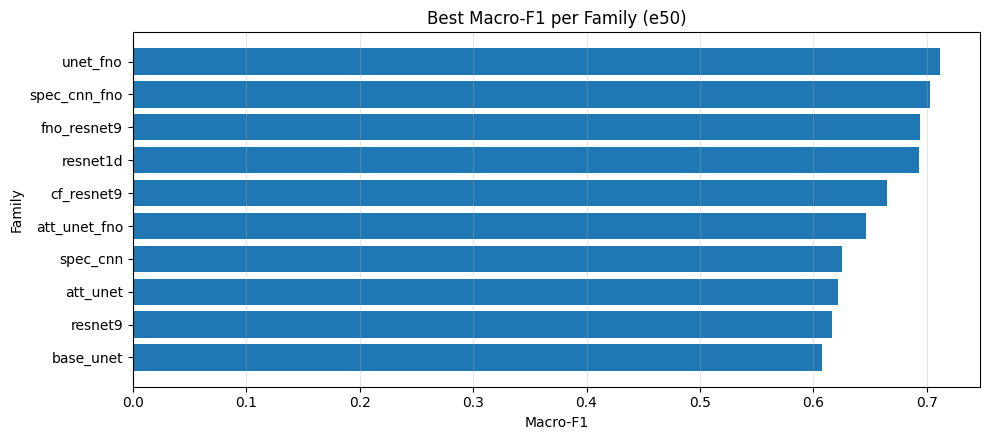

In [172]:
# ===========================================================
# Compare regimes within each family (using best per regime)
#   Table + quick plot (macro-F1)
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_REGIME_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"

if not BEST_REGIME_PATH.exists():
    raise FileNotFoundError(f"Missing: {BEST_REGIME_PATH}. Run evaluation first.")

df_best_regime = pd.read_csv(BEST_REGIME_PATH)

required = {"family", "train_regime", "macro_f1"}
missing = required - set(df_best_regime.columns)
if missing:
    raise RuntimeError(f"eval_best_per_family_per_regime.csv missing required columns: {missing}")

df_best_regime = df_best_regime.copy()
df_best_regime["family"] = df_best_regime["family"].astype(str).str.strip()
df_best_regime["train_regime"] = df_best_regime["train_regime"].astype(str).str.strip()
df_best_regime["macro_f1"] = pd.to_numeric(df_best_regime["macro_f1"], errors="coerce")
df_best_regime = df_best_regime.dropna(subset=["macro_f1"])

if df_best_regime.empty:
    raise RuntimeError("No valid rows found in eval_best_per_family_per_regime.csv after cleaning macro_f1.")

# Pivot table: rows=family, cols=regime, values=macro_f1
pivot = df_best_regime.pivot_table(
    index="family",
    columns="train_regime",
    values="macro_f1",
    aggfunc="max"
).sort_index()

display(pivot)

regimes = sorted(df_best_regime["train_regime"].unique().tolist())

if len(regimes) == 1:
    # With one regime, a ranked family bar chart is more informative than one-point lines.
    regime = regimes[0]
    plot_df = (
        df_best_regime[df_best_regime["train_regime"] == regime]
        .sort_values("macro_f1", ascending=False)
        .reset_index(drop=True)
    )

    plt.figure(figsize=(10, max(4, 0.45 * len(plot_df))))
    plt.barh(plot_df["family"], plot_df["macro_f1"])
    plt.gca().invert_yaxis()
    plt.title(f"Best Macro-F1 per Family ({regime})")
    plt.xlabel("Macro-F1")
    plt.ylabel("Family")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    plt.figure(figsize=(10, max(4, 0.7 * len(pivot.index))))
    for fam in list(pivot.index):
        vals = pivot.loc[fam].dropna()
        xs = list(vals.index)
        ys = list(vals.values)
        plt.plot(xs, ys, marker="o", label=fam)

    plt.title("Best Macro-F1 per Training Regime")
    plt.ylabel("Macro-F1")
    plt.xlabel("Training Regime")
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


In [173]:
# ===========================================================
# Best overall per family (best regime picked per family)
#   -> models/<DATASET_NAME>/eval_best_overall_per_family.csv
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_REGIME_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"
OUT_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"

if not BEST_REGIME_PATH.exists():
    raise FileNotFoundError(f"Missing: {BEST_REGIME_PATH}. Run evaluation first.")

df_best_regime = pd.read_csv(BEST_REGIME_PATH)

required = {"family", "train_regime", "macro_f1"}
missing = required - set(df_best_regime.columns)
if missing:
    raise RuntimeError(f"eval_best_per_family_per_regime.csv missing required columns: {missing}")

df_best_regime = df_best_regime.copy()
df_best_regime["family"] = df_best_regime["family"].astype(str).str.strip()
df_best_regime["train_regime"] = df_best_regime["train_regime"].astype(str).str.strip()

for col in ["macro_f1", "balanced_acc", "test_acc", "val_acc", "params_million"]:
    if col in df_best_regime.columns:
        df_best_regime[col] = pd.to_numeric(df_best_regime[col], errors="coerce")

df_best_regime = df_best_regime.dropna(subset=["macro_f1"])
if df_best_regime.empty:
    raise RuntimeError("No valid rows found in eval_best_per_family_per_regime.csv after cleaning macro_f1.")

sort_cols = ["macro_f1"]
ascending = [False]
for tie_col in ["balanced_acc", "test_acc", "val_acc", "params_million"]:
    if tie_col in df_best_regime.columns:
        sort_cols.append(tie_col)
        # Prefer stronger metrics, then smaller models if all else is tied.
        ascending.append(True if tie_col == "params_million" else False)

best_overall = (
    df_best_regime.sort_values(sort_cols, ascending=ascending)
                  .groupby("family", as_index=False, group_keys=False)
                  .head(1)
                  .reset_index(drop=True)
)

best_overall.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)
print("Rows:", len(best_overall), "| families:", sorted(best_overall["family"].unique().tolist()))

best_overall


Saved: models\ECG5000\eval_best_overall_per_family.csv
Rows: 10 | families: ['att_unet', 'att_unet_fno', 'base_unet', 'cf_resnet9', 'fno_resnet9', 'resnet1d', 'resnet9', 'spec_cnn', 'spec_cnn_fno', 'unet_fno']


,family,train_regime,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,...,val_acc,epochs_ran,test_loss,modes,fno_layers,n_fft,hop_length,modes_h,modes_w,fno_layers_2d
0,unet_fno,e50,models/ECG5000/unet_fno/e50/run_096,run_096,32,0.0010,0.0001,0.0,0.954,0.711338,...,0.964,50,0.222968,24.0,2.0,NaN,NaN,NaN,NaN,NaN
1,spec_cnn_fno,e50,models/ECG5000/spec_cnn_fno/e50/run_1981,run_1981,48,0.0010,0.0001,0.0,0.959,0.702450,...,0.961,50,0.270206,NaN,NaN,32.0,16.0,16.0,8.0,2.0
2,fno_resnet9,e50,models/ECG5000/fno_resnet9/e50/run_081,run_081,32,0.0010,0.0000,0.1,0.951,0.694010,...,0.966,50,0.256617,16.0,1.0,NaN,NaN,NaN,NaN,NaN
3,resnet1d,e50,models/ECG5000/resnet1d/e50/run_005,run_005,16,0.0010,0.0001,0.1,0.956,0.692740,...,0.961,50,0.189174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cf_resnet9,e50,models/ECG5000/cf_resnet9/e50/run_045,run_045,32,0.0010,0.0000,0.2,0.953,0.664949,...,0.969,50,0.216762,24.0,NaN,NaN,NaN,NaN,NaN,NaN
5,att_unet_fno,e50,models/ECG5000/att_unet_fno/e50/run_163,run_163,48,0.0010,0.0001,0.0,0.959,0.646302,...,0.965,50,0.166509,8.0,1.0,NaN,NaN,NaN,NaN,NaN
6,spec_cnn,e50,models/ECG5000/spec_cnn/e50/run_177,run_177,48,0.0010,0.0001,0.2,0.955,0.625631,...,0.955,50,0.296432,NaN,NaN,32.0,16.0,NaN,NaN,NaN
7,att_unet,e50,models/ECG5000/att_unet/e50/run_036,run_036,48,0.0005,0.0001,0.2,0.958,0.621405,...,0.961,50,0.172656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,resnet9,e50,models/ECG5000/resnet9/e50/run_015,run_015,32,0.0010,0.0000,0.2,0.952,0.616415,...,0.964,50,0.171480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,base_unet,e50,models/ECG5000/base_unet/e50/run_031,run_031,48,0.0005,0.0000,0.0,0.957,0.607462,...,0.962,50,0.197260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [174]:
# ===========================================================
# Param-matched best models (ALL runs, cross-family)
# Adds reference metrics in each row for direct comparison
#
# Output:
#   models/<DATASET_NAME>/param_matched_cross_family.csv
# ===========================================================

import pandas as pd
from pathlib import Path
import numpy as np

MODELS_DIR = Path("models") / DATASET_NAME
ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
OUT_PATH = MODELS_DIR / "param_matched_cross_family.csv"
PAIR_OUT_PATH = MODELS_DIR / "paired_fno_comparison.csv"

TOL = 0.10  # +/-10%

if not ALL_PATH.exists():
    raise FileNotFoundError(f"Missing: {ALL_PATH}. Run evaluation first.")

df = pd.read_csv(ALL_PATH)

required = {"family", "macro_f1", "balanced_acc", "test_acc", "params_million", "train_regime", "run_dir"}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"eval_stats_all.csv missing required columns: {missing}")

# Clean + ensure numeric
df = df.copy()
df["family"] = df["family"].astype(str).str.strip()
df["train_regime"] = df["train_regime"].astype(str).str.strip()
for col in ["params_million", "macro_f1", "balanced_acc", "test_acc", "val_acc"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["params_million", "macro_f1", "balanced_acc", "test_acc"])
if df.empty:
    raise RuntimeError("No valid rows found in eval_stats_all.csv after cleaning required metrics.")

families = sorted(df["family"].unique().tolist())

sort_cols = ["macro_f1", "balanced_acc", "test_acc"]
ascending = [False, False, False]
if "val_acc" in df.columns:
    sort_cols.append("val_acc")
    ascending.append(False)
sort_cols.append("params_million")
ascending.append(True)

# Best run overall per family (reference points), with deterministic tie-breaking:
# macro_f1 desc -> balanced_acc desc -> test_acc desc -> val_acc desc -> params_million asc.
best_overall = (
    df.sort_values(sort_cols, ascending=ascending)
      .groupby("family", as_index=False, group_keys=False)
      .head(1)
      .reset_index(drop=True)
)

rows = []

for _, ref in best_overall.iterrows():
    ref_family = ref["family"]
    ref_params = float(ref["params_million"])
    lo, hi = ref_params * (1 - TOL), ref_params * (1 + TOL)

    ref_pack = {
        "reference_family": ref_family,
        "ref_params_million": ref_params,
        "ref_macro_f1": float(ref["macro_f1"]),
        "ref_balanced_acc": float(ref["balanced_acc"]),
        "ref_test_acc": float(ref["test_acc"]),
        "ref_val_acc": float(ref["val_acc"]) if "val_acc" in ref and pd.notna(ref["val_acc"]) else np.nan,
        "ref_train_regime": ref.get("train_regime", "unknown"),
        "ref_run_id": ref.get("run_id", ""),
        "ref_run_dir": ref.get("run_dir", ""),
    }

    # Reference row (self)
    rows.append({
        **ref_pack,
        "target_family": ref_family,
        "matched": True,
        "target_params_million": ref_params,
        "param_ratio": 1.0,
        "target_macro_f1": float(ref["macro_f1"]),
        "target_balanced_acc": float(ref["balanced_acc"]),
        "target_test_acc": float(ref["test_acc"]),
        "target_val_acc": float(ref["val_acc"]) if "val_acc" in ref and pd.notna(ref["val_acc"]) else np.nan,
        "target_train_regime": ref.get("train_regime", "unknown"),
        "target_run_id": ref.get("run_id", ""),
        "target_run_dir": ref.get("run_dir", ""),
    })

    # Match other families within +/- TOL of the reference parameter count.
    for fam in families:
        if fam == ref_family:
            continue

        sub = df[df["family"] == fam]
        sub = sub[(sub["params_million"] >= lo) & (sub["params_million"] <= hi)]

        if sub.empty:
            rows.append({
                **ref_pack,
                "target_family": fam,
                "matched": False,
                "target_params_million": np.nan,
                "param_ratio": np.nan,
                "target_macro_f1": np.nan,
                "target_balanced_acc": np.nan,
                "target_test_acc": np.nan,
                "target_val_acc": np.nan,
                "target_train_regime": "",
                "target_run_id": "",
                "target_run_dir": "",
            })
            continue

        best_match = sub.sort_values(sort_cols, ascending=ascending).iloc[0]
        tparams = float(best_match["params_million"])

        rows.append({
            **ref_pack,
            "target_family": fam,
            "matched": True,
            "target_params_million": tparams,
            "param_ratio": tparams / ref_params if ref_params > 0 else np.nan,
            "target_macro_f1": float(best_match["macro_f1"]),
            "target_balanced_acc": float(best_match["balanced_acc"]),
            "target_test_acc": float(best_match["test_acc"]),
            "target_val_acc": float(best_match["val_acc"]) if "val_acc" in best_match and pd.notna(best_match["val_acc"]) else np.nan,
            "target_train_regime": best_match.get("train_regime", "unknown"),
            "target_run_id": best_match.get("run_id", ""),
            "target_run_dir": best_match.get("run_dir", ""),
        })

out = pd.DataFrame(rows)

# Useful delta columns (target - reference); positive means target outperformed the reference.
out["delta_macro_f1"] = out["target_macro_f1"] - out["ref_macro_f1"]
out["delta_balanced_acc"] = out["target_balanced_acc"] - out["ref_balanced_acc"]
out["delta_test_acc"] = out["target_test_acc"] - out["ref_test_acc"]

out = out.sort_values(
    ["reference_family", "matched", "target_macro_f1"],
    ascending=[True, False, False]
).reset_index(drop=True)

out.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)
print("Rows:", len(out), "| references:", out["reference_family"].nunique(), "| matched rows:", int(out["matched"].sum()))

# Focused paired comparisons for the paper's main FNO question.
# The strict cross-family table above uses TOL=10%. Here we evaluate paired
# baseline-vs-FNO comparisons at multiple parameter tolerances.
PAIR_TOLS = [0.10, 0.15, 0.20]
PAIR_DEFINITIONS = [
    ("base_unet", "unet_fno", "U-Net vs U-Net-FNO"),
    ("att_unet", "att_unet_fno", "Attention U-Net vs Attention U-Net-FNO"),
    ("resnet9", "cf_resnet9", "ResNet9 vs CF-ResNet9"),
    ("resnet9", "fno_resnet9", "ResNet9 vs FNO-ResNet9"),
    ("spec_cnn", "spec_cnn_fno", "Spectrogram CNN vs Spectrogram CNN-FNO"),
]

pair_rows = []

for tol in PAIR_TOLS:
    for baseline_family, fno_family, comparison in PAIR_DEFINITIONS:
        base_candidates = best_overall[best_overall["family"] == baseline_family]
        if base_candidates.empty:
            pair_rows.append({
                "comparison": comparison,
                "tolerance": tol,
                "tolerance_pct": int(round(tol * 100)),
                "baseline_family": baseline_family,
                "fno_family": fno_family,
                "matched": False,
                "reason": "missing baseline family",
            })
            continue

        base = base_candidates.iloc[0]
        base_params = float(base["params_million"])
        lo, hi = base_params * (1 - tol), base_params * (1 + tol)

        fno_candidates = df[df["family"] == fno_family]
        fno_candidates = fno_candidates[(fno_candidates["params_million"] >= lo) & (fno_candidates["params_million"] <= hi)]

        if fno_candidates.empty:
            pair_rows.append({
                "comparison": comparison,
                "tolerance": tol,
                "tolerance_pct": int(round(tol * 100)),
                "baseline_family": baseline_family,
                "fno_family": fno_family,
                "matched": False,
                "reason": f"no FNO-family run within +/-{int(round(tol * 100))}% params",
                "baseline_params_million": base_params,
                "baseline_macro_f1": float(base["macro_f1"]),
                "baseline_balanced_acc": float(base["balanced_acc"]),
                "baseline_test_acc": float(base["test_acc"]),
                "baseline_train_regime": base.get("train_regime", "unknown"),
                "baseline_run_id": base.get("run_id", ""),
                "baseline_run_dir": base.get("run_dir", ""),
                "fno_params_million": np.nan,
                "param_ratio": np.nan,
                "fno_macro_f1": np.nan,
                "fno_balanced_acc": np.nan,
                "fno_test_acc": np.nan,
                "fno_train_regime": "",
                "fno_run_id": "",
                "fno_run_dir": "",
            })
            continue

        fno = fno_candidates.sort_values(sort_cols, ascending=ascending).iloc[0]
        fno_params = float(fno["params_million"])

        pair_rows.append({
            "comparison": comparison,
            "tolerance": tol,
            "tolerance_pct": int(round(tol * 100)),
            "baseline_family": baseline_family,
            "fno_family": fno_family,
            "matched": True,
            "reason": "matched within parameter tolerance",
            "baseline_params_million": base_params,
            "fno_params_million": fno_params,
            "param_ratio": fno_params / base_params if base_params > 0 else np.nan,
            "baseline_macro_f1": float(base["macro_f1"]),
            "fno_macro_f1": float(fno["macro_f1"]),
            "delta_macro_f1": float(fno["macro_f1"] - base["macro_f1"]),
            "baseline_balanced_acc": float(base["balanced_acc"]),
            "fno_balanced_acc": float(fno["balanced_acc"]),
            "delta_balanced_acc": float(fno["balanced_acc"] - base["balanced_acc"]),
            "baseline_test_acc": float(base["test_acc"]),
            "fno_test_acc": float(fno["test_acc"]),
            "delta_test_acc": float(fno["test_acc"] - base["test_acc"]),
            "baseline_val_acc": float(base["val_acc"]) if "val_acc" in base and pd.notna(base["val_acc"]) else np.nan,
            "fno_val_acc": float(fno["val_acc"]) if "val_acc" in fno and pd.notna(fno["val_acc"]) else np.nan,
            "baseline_train_regime": base.get("train_regime", "unknown"),
            "fno_train_regime": fno.get("train_regime", "unknown"),
            "baseline_run_id": base.get("run_id", ""),
            "fno_run_id": fno.get("run_id", ""),
            "baseline_run_dir": base.get("run_dir", ""),
            "fno_run_dir": fno.get("run_dir", ""),
        })

paired = pd.DataFrame(pair_rows)
paired = paired.sort_values(["comparison", "tolerance_pct"]).reset_index(drop=True)
paired.to_csv(PAIR_OUT_PATH, index=False)
print("Saved:", PAIR_OUT_PATH)
print("Paired comparisons:", len(paired), "| matched:", int(paired["matched"].sum()) if "matched" in paired else 0)
print("Matched by tolerance:")
print(paired.groupby("tolerance_pct")["matched"].sum().to_string())

cols_show = [
    "reference_family", "target_family", "matched",
    "ref_params_million", "target_params_million", "param_ratio",
    "ref_macro_f1", "target_macro_f1", "delta_macro_f1",
    "ref_balanced_acc", "target_balanced_acc", "delta_balanced_acc",
    "ref_train_regime", "target_train_regime",
]
display(out[cols_show])
paired


Saved: models\ECG5000\param_matched_cross_family.csv
Rows: 100 | references: 10 | matched rows: 33
Saved: models\ECG5000\paired_fno_comparison.csv
Paired comparisons: 15 | matched: 4
Matched by tolerance:
tolerance_pct
10    0
15    1
20    3


,reference_family,target_family,matched,ref_params_million,target_params_million,param_ratio,ref_macro_f1,target_macro_f1,delta_macro_f1,ref_balanced_acc,target_balanced_acc,delta_balanced_acc,ref_train_regime,target_train_regime
0,att_unet,fno_resnet9,True,0.379475,0.366533,0.965895,0.621405,0.674660,0.053255,0.584482,0.626480,0.041999,e50,e50
1,att_unet,cf_resnet9,True,0.379475,0.343925,0.906318,0.621405,0.659065,0.037659,0.584482,0.620146,0.035665,e50,e50
2,att_unet,att_unet,True,0.379475,0.379475,1.000000,0.621405,0.621405,0.000000,0.584482,0.584482,0.000000,e50,e50
3,att_unet,base_unet,True,0.379475,0.367445,0.968298,0.621405,0.607462,-0.013944,0.584482,0.559434,-0.025048,e50,e50
4,att_unet,att_unet_fno,False,0.379475,NaN,NaN,0.621405,NaN,NaN,0.584482,NaN,NaN,e50,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,unet_fno,base_unet,False,0.984037,NaN,NaN,0.711338,NaN,NaN,0.665644,NaN,NaN,e50,
96,unet_fno,cf_resnet9,False,0.984037,NaN,NaN,0.711338,NaN,NaN,0.665644,NaN,NaN,e50,
97,unet_fno,fno_resnet9,False,0.984037,NaN,NaN,0.711338,NaN,NaN,0.665644,NaN,NaN,e50,
98,unet_fno,resnet9,False,0.984037,NaN,NaN,0.711338,NaN,NaN,0.665644,NaN,NaN,e50,


,comparison,tolerance,tolerance_pct,baseline_family,fno_family,matched,reason,baseline_params_million,baseline_macro_f1,baseline_balanced_acc,...,fno_balanced_acc,fno_test_acc,fno_train_regime,fno_run_id,fno_run_dir,delta_macro_f1,delta_balanced_acc,delta_test_acc,baseline_val_acc,fno_val_acc
0,Attention U-Net vs Attention U-Net-FNO,0.10,10,att_unet,att_unet_fno,False,no FNO-family run within +/-10% params,0.379475,0.621405,0.584482,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
1,Attention U-Net vs Attention U-Net-FNO,0.15,15,att_unet,att_unet_fno,False,no FNO-family run within +/-15% params,0.379475,0.621405,0.584482,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
2,Attention U-Net vs Attention U-Net-FNO,0.20,20,att_unet,att_unet_fno,True,matched within parameter tolerance,0.379475,0.621405,0.584482,...,0.603565,0.958,e50,run_123,models/ECG5000/att_unet_fno/e50/run_123,0.007193,0.019083,0.000,0.961,0.963
3,ResNet9 vs CF-ResNet9,0.10,10,resnet9,cf_resnet9,False,no FNO-family run within +/-10% params,0.066277,0.616415,0.601002,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
4,ResNet9 vs CF-ResNet9,0.15,15,resnet9,cf_resnet9,False,no FNO-family run within +/-15% params,0.066277,0.616415,0.601002,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
5,ResNet9 vs CF-ResNet9,0.20,20,resnet9,cf_resnet9,False,no FNO-family run within +/-20% params,0.066277,0.616415,0.601002,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
6,ResNet9 vs FNO-ResNet9,0.10,10,resnet9,fno_resnet9,False,no FNO-family run within +/-10% params,0.066277,0.616415,0.601002,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN
7,ResNet9 vs FNO-ResNet9,0.15,15,resnet9,fno_resnet9,True,matched within parameter tolerance,0.066277,0.616415,0.601002,...,0.620246,0.953,e50,run_048,models/ECG5000/fno_resnet9/e50/run_048,0.040248,0.019244,0.001,0.964,0.966
8,ResNet9 vs FNO-ResNet9,0.20,20,resnet9,fno_resnet9,True,matched within parameter tolerance,0.066277,0.616415,0.601002,...,0.620246,0.953,e50,run_048,models/ECG5000/fno_resnet9/e50/run_048,0.040248,0.019244,0.001,0.964,0.966
9,Spectrogram CNN vs Spectrogram CNN-FNO,0.10,10,spec_cnn,spec_cnn_fno,False,no FNO-family run within +/-10% params,0.209765,0.625631,0.601865,...,NaN,NaN,,,,NaN,NaN,NaN,NaN,NaN


### Plots for evaluation

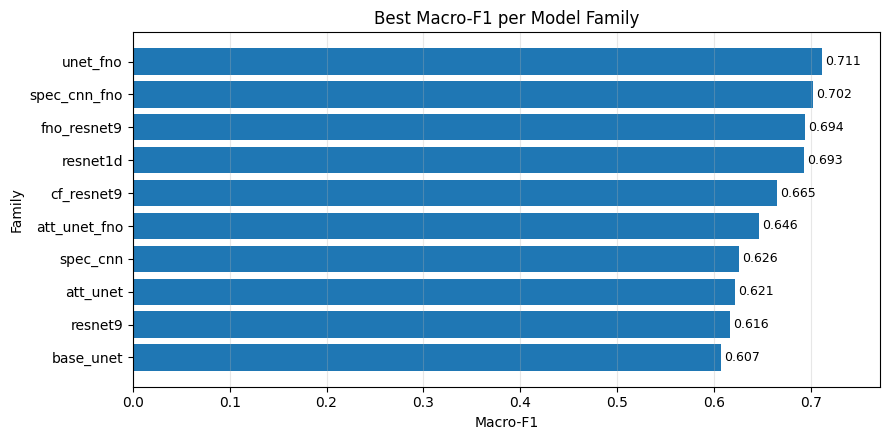

,family,train_regime,macro_f1,balanced_acc,test_acc,params_million,run_dir
0,unet_fno,e50,0.711338,0.665644,0.954,0.984037,models/ECG5000/unet_fno/e50/run_096
1,spec_cnn_fno,e50,0.702450,0.644401,0.959,9.721829,models/ECG5000/spec_cnn_fno/e50/run_1981
2,fno_resnet9,e50,0.694010,0.651096,0.951,0.122501,models/ECG5000/fno_resnet9/e50/run_081
3,resnet1d,e50,0.692740,0.631905,0.956,0.242773,models/ECG5000/resnet1d/e50/run_005
4,cf_resnet9,e50,0.664949,0.631878,0.953,0.194469,models/ECG5000/cf_resnet9/e50/run_045
5,att_unet_fno,e50,0.646302,0.634847,0.959,0.711827,models/ECG5000/att_unet_fno/e50/run_163
6,spec_cnn,e50,0.625631,0.601865,0.955,0.209765,models/ECG5000/spec_cnn/e50/run_177
7,att_unet,e50,0.621405,0.584482,0.958,0.379475,models/ECG5000/att_unet/e50/run_036
8,resnet9,e50,0.616415,0.601002,0.952,0.066277,models/ECG5000/resnet9/e50/run_015
9,base_unet,e50,0.607462,0.559434,0.957,0.367445,models/ECG5000/base_unet/e50/run_031


In [175]:
# ===========================================================
# Plot: Best overall Macro-F1 per family (best regime chosen)
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_OVERALL_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"

if not BEST_OVERALL_PATH.exists():
    raise FileNotFoundError(f"Missing: {BEST_OVERALL_PATH}. Run the best-overall cell first.")

df = pd.read_csv(BEST_OVERALL_PATH)

required = {"family", "train_regime", "macro_f1", "balanced_acc", "test_acc", "params_million", "run_dir"}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"eval_best_overall_per_family.csv missing required columns: {missing}")

df = df.copy()
df["family"] = df["family"].astype(str).str.strip()
df["train_regime"] = df["train_regime"].astype(str).str.strip()
for col in ["macro_f1", "balanced_acc", "test_acc", "params_million"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["macro_f1", "balanced_acc", "test_acc", "params_million"])
if df.empty:
    raise RuntimeError("No valid rows found in eval_best_overall_per_family.csv after cleaning metrics.")

df = df.sort_values("macro_f1", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, max(4, 0.45 * len(df))))
bars = plt.barh(df["family"], df["macro_f1"])
plt.gca().invert_yaxis()
plt.xlabel("Macro-F1")
plt.ylabel("Family")
plt.title("Best Macro-F1 per Model Family")
plt.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, df["macro_f1"]):
    plt.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=9,
    )

plt.xlim(0, min(1.0, max(0.75, float(df["macro_f1"].max()) + 0.06)))
plt.tight_layout()
plt.show()

df[["family", "train_regime", "macro_f1", "balanced_acc", "test_acc", "params_million", "run_dir"]]


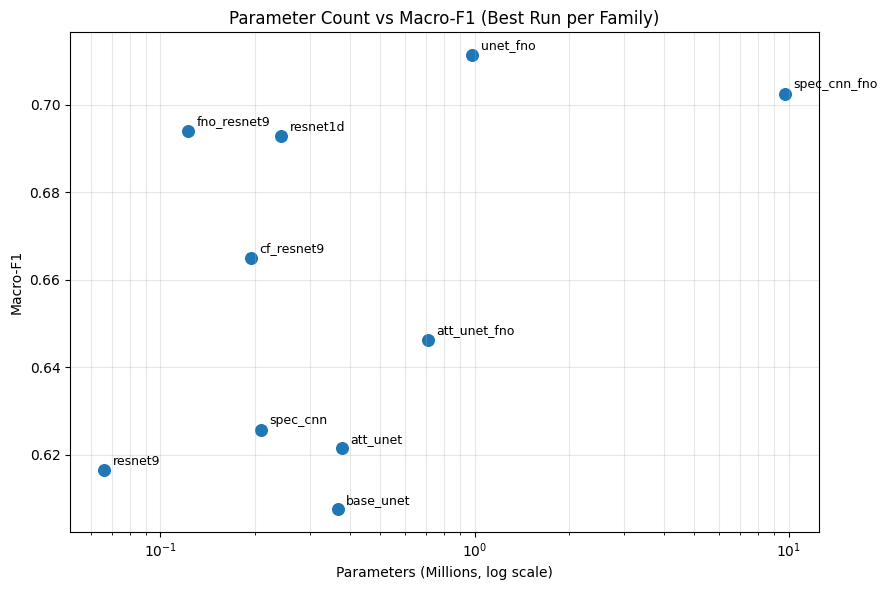

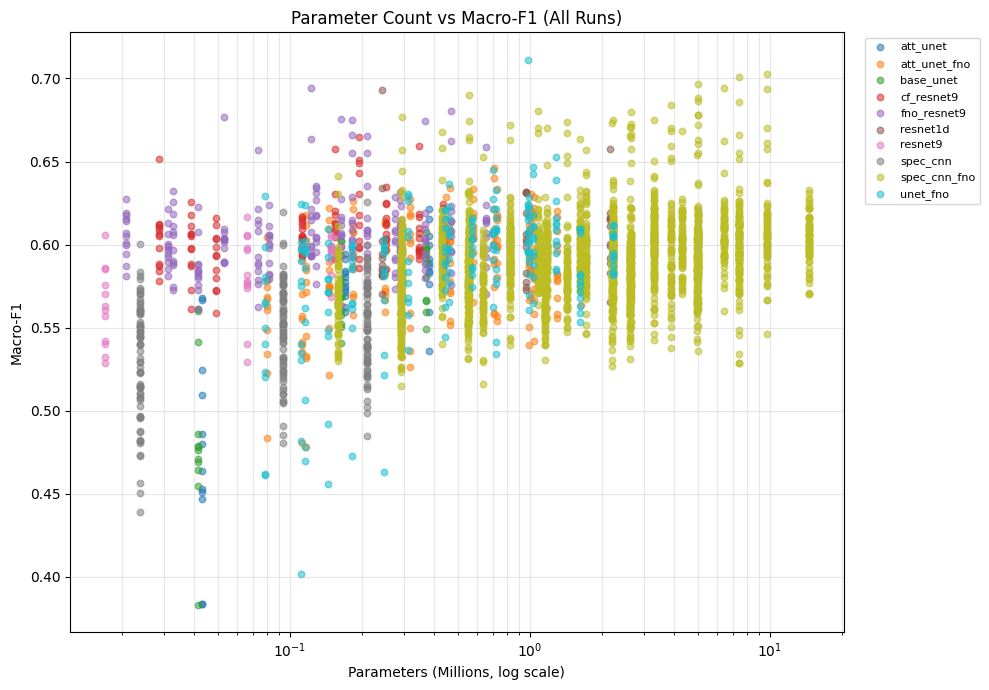

,family,params_million,macro_f1
0,unet_fno,0.984037,0.711338
1,spec_cnn_fno,9.721829,0.702450
2,fno_resnet9,0.122501,0.694010
3,resnet1d,0.242773,0.692740
4,cf_resnet9,0.194469,0.664949
5,att_unet_fno,0.711827,0.646302
6,spec_cnn,0.209765,0.625631
7,att_unet,0.379475,0.621405
8,resnet9,0.066277,0.616415
9,base_unet,0.367445,0.607462


In [176]:
# ===========================================================
# Params vs Macro-F1
#   A) Best overall run per family
#   B) All evaluated runs
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_OVERALL_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"
EVAL_ALL_PATH = MODELS_DIR / "eval_stats_all.csv"


def _load_params_macro(path: Path, label: str):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}. Run the required evaluation cells first.")

    df = pd.read_csv(path)
    required = {"family", "params_million", "macro_f1"}
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{label} missing required columns: {missing}")

    df = df.copy()
    df["family"] = df["family"].astype(str).str.strip()
    df["params_million"] = pd.to_numeric(df["params_million"], errors="coerce")
    df["macro_f1"] = pd.to_numeric(df["macro_f1"], errors="coerce")
    df = df.dropna(subset=["params_million", "macro_f1"])

    if df.empty:
        raise RuntimeError(f"No valid rows found in {label} after cleaning params_million/macro_f1.")

    return df


# A) Best overall run per family: clean manuscript-facing view.
df_best = _load_params_macro(BEST_OVERALL_PATH, "eval_best_overall_per_family.csv")
df_best = df_best.sort_values("macro_f1", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 6))
plt.scatter(df_best["params_million"], df_best["macro_f1"], s=70)

for _, row in df_best.iterrows():
    plt.annotate(
        row["family"],
        (row["params_million"], row["macro_f1"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=9,
    )

plt.xscale("log")
plt.xlabel("Parameters (Millions, log scale)")
plt.ylabel("Macro-F1")
plt.title("Parameter Count vs Macro-F1 (Best Run per Family)")
plt.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

# B) All runs: search-space view.
df_all = _load_params_macro(EVAL_ALL_PATH, "eval_stats_all.csv")
families = sorted(df_all["family"].unique().tolist())

plt.figure(figsize=(10, 7))
for fam in families:
    sub = df_all[df_all["family"] == fam]
    plt.scatter(
        sub["params_million"],
        sub["macro_f1"],
        label=fam,
        s=22,
        alpha=0.55,
    )

plt.xscale("log")
plt.xlabel("Parameters (Millions, log scale)")
plt.ylabel("Macro-F1")
plt.title("Parameter Count vs Macro-F1 (All Runs)")
plt.grid(alpha=0.3, which="both")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

df_best[["family", "params_million", "macro_f1"]]


<Figure size 1000x600 with 0 Axes>

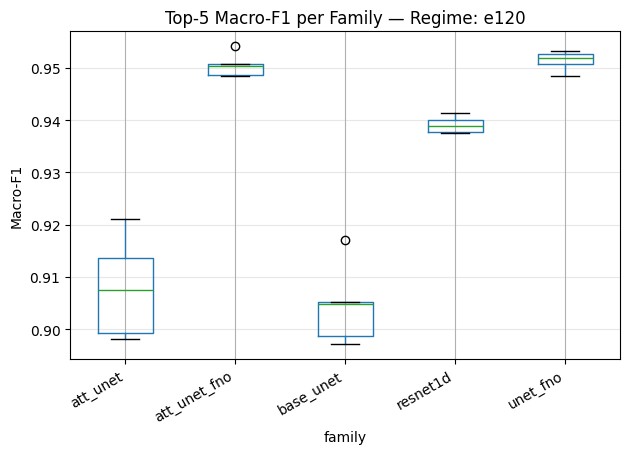

<Figure size 1000x600 with 0 Axes>

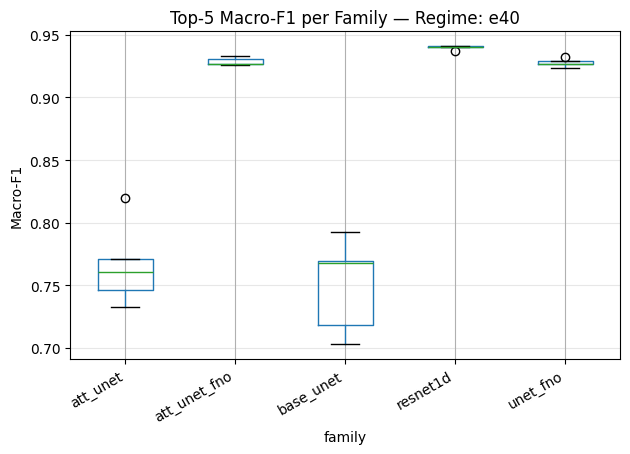

<Figure size 1000x600 with 0 Axes>

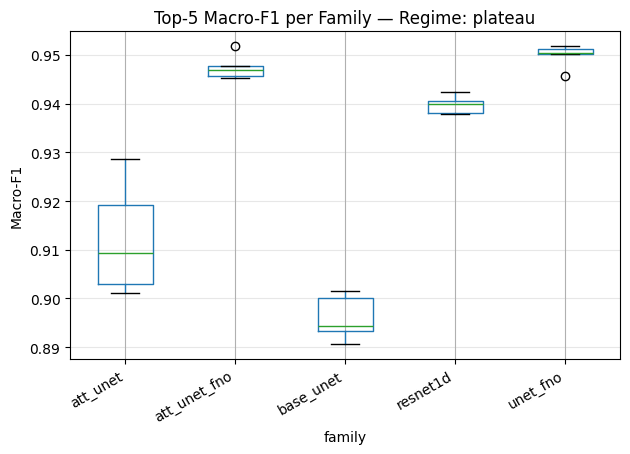

In [25]:
# ===========================================================
# Boxplots: Top-k Macro-F1 per family, per regime
#   Uses: top5_per_family_per_regime.csv
# ===========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
TOP5_REGIME_PATH = MODELS_DIR / "top5_per_family_per_regime.csv"

if not TOP5_REGIME_PATH.exists():
    raise FileNotFoundError(f"Missing: {TOP5_REGIME_PATH}. Run the top-k cell first.")

df = pd.read_csv(TOP5_REGIME_PATH)

required = {"family", "train_regime", "macro_f1"}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"top5_per_family_per_regime.csv missing required columns: {missing}")

df = df.copy()
df["family"] = df["family"].astype(str).str.strip()
df["train_regime"] = df["train_regime"].astype(str).str.strip()
df["macro_f1"] = pd.to_numeric(df["macro_f1"], errors="coerce")
if "rank_in_group" in df.columns:
    df["rank_in_group"] = pd.to_numeric(df["rank_in_group"], errors="coerce")

df = df.dropna(subset=["macro_f1"])
if df.empty:
    raise RuntimeError("No valid rows found in top5_per_family_per_regime.csv after cleaning macro_f1.")

for regime in sorted(df["train_regime"].unique()):
    sub = df[df["train_regime"] == regime].copy()

    # Keep baseline/FNO counterparts next to each other for easier interpretation.
    preferred_pairs = [
        "base_unet", "unet_fno",
        "att_unet", "att_unet_fno",
        "resnet9", "cf_resnet9", "fno_resnet9",
        "spec_cnn", "spec_cnn_fno", "spec_vit",
        "resnet1d",
    ]
    present = set(sub["family"].unique())
    family_order = [fam for fam in preferred_pairs if fam in present]

    # Append any unexpected families by best top-k value, then median.
    remaining = sorted(present - set(family_order))
    if remaining:
        ranked_remaining = (
            sub[sub["family"].isin(remaining)]
            .groupby("family")["macro_f1"]
            .agg(best="max", median="median")
            .sort_values(["best", "median"], ascending=False)
            .index
            .tolist()
        )
        family_order.extend(ranked_remaining)

    data = [sub.loc[sub["family"] == fam, "macro_f1"].values for fam in family_order]

    plt.figure(figsize=(max(10, 0.75 * len(family_order)), 6))
    ax = plt.gca()
    ax.boxplot(data, labels=family_order, showmeans=True)

    # Overlay individual top-k points with deterministic horizontal jitter.
    rng = np.random.default_rng(42)
    for i, fam in enumerate(family_order, start=1):
        vals = sub.loc[sub["family"] == fam, "macro_f1"].values
        jitter = rng.uniform(-0.08, 0.08, size=len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, s=28, alpha=0.75, zorder=3)

    ax.set_title(f"Top-5 Macro-F1 per Family ? Regime: {regime}")
    ax.set_ylabel("Macro-F1")
    ax.set_xlabel("Family")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


In [26]:
# ===========================================================
# Export evaluation figures to JPGs into figs/<DATASET_NAME>/
#
# Inputs:
#   models/<DATASET_NAME>/eval_stats_all.csv
#   models/<DATASET_NAME>/eval_best_overall_per_family.csv
#   models/<DATASET_NAME>/top5_per_family_per_regime.csv
#
# Outputs:
#   confusion_<family>.jpg                  (one per family, high-res, annotated)
#   per_class_f1.jpg OR per_class_f1_partXX.jpg
#   top5_boxplot_overall.jpg
#   top5_boxplot_per_regime__<regime>.jpg
#   params_vs_macroF1_best_overall.jpg
#   params_vs_macroF1_all_runs.jpg
#   regime_wins_per_family.jpg
#   best_macroF1_heatmap_family_by_regime.jpg
# ===========================================================

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

# ---------- Paths ----------
MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
BEST_OVERALL_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"
TOP5_REGIME_PATH = MODELS_DIR / "top5_per_family_per_regime.csv"
FIG_DIR = Path("figs") / DATASET_NAME
FIG_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

families_order = [
    "base_unet", "unet_fno",
    "att_unet", "att_unet_fno",
    "resnet9", "cf_resnet9", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit",
    "resnet1d",
]
pretty_names = {
    "base_unet": "U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d": "ResNet1D",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "fno_resnet9": "FNO-ResNet9",
    "spec_cnn": "Spectrogram CNN",
    "spec_cnn_fno": "Spectrogram CNN + FNO",
    "spec_vit": "Spectrogram ViT",
}


def ordered_families(families):
    present = set(str(f).strip() for f in families)
    ordered = [fam for fam in families_order if fam in present]
    ordered.extend(sorted(present - set(ordered)))
    return ordered


def require_file(path: Path, hint: str):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}. {hint}")


def clean_eval_table(df: pd.DataFrame, source_name: str):
    required = {"family", "train_regime", "run_dir", "macro_f1"}
    missing = required - set(df.columns)
    if missing:
        raise RuntimeError(f"{source_name} missing required columns: {missing}")

    df = df.copy()
    df["family"] = df["family"].astype(str).str.strip()
    df["train_regime"] = df["train_regime"].astype(str).str.strip()
    for col in ["macro_f1", "balanced_acc", "test_acc", "val_acc", "params_million"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["macro_f1"])
    if df.empty:
        raise RuntimeError(f"No valid rows in {source_name} after cleaning macro_f1.")
    return df


def torch_load_state_dict(weights_path: Path, device=device):
    try:
        return torch.load(weights_path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(weights_path, map_location=device)


# ---------- Load tables ----------
require_file(EVAL_ALL_PATH, "Run the all-run evaluation cell first.")
require_file(BEST_OVERALL_PATH, "Run the best-overall cell first.")

df_all = clean_eval_table(pd.read_csv(EVAL_ALL_PATH), "eval_stats_all.csv")
df_best_overall = clean_eval_table(pd.read_csv(BEST_OVERALL_PATH), "eval_best_overall_per_family.csv")

fams_available = ordered_families(df_best_overall["family"].unique())
df_best_overall["family"] = pd.Categorical(df_best_overall["family"], fams_available, ordered=True)
df_best_overall = df_best_overall.sort_values("family").reset_index(drop=True)

print("Families for plotting:", fams_available)
print("Regimes seen:", sorted(df_all["train_regime"].dropna().unique().tolist()))
display_cols = ["family", "train_regime", "macro_f1", "balanced_acc", "test_acc", "params_million", "run_dir"]
display(df_best_overall[[c for c in display_cols if c in df_best_overall.columns]])


# ---------- Helpers ----------
def load_model_from_run_dir(family: str, run_dir: str):
    run_dir = Path(str(run_dir))
    cfg_path = run_dir / "config.json"
    weights_path = run_dir / "model.pt"

    if not cfg_path.exists():
        raise FileNotFoundError(f"Missing config.json: {cfg_path}")
    if not weights_path.exists():
        raise FileNotFoundError(f"Missing model.pt: {weights_path}")

    with open(cfg_path, "r") as f:
        cfg = json.load(f)

    # Keep regime consistent with folder/table when available.
    parts = run_dir.parts
    if len(parts) >= 2:
        cfg["train_regime"] = cfg.get("train_regime", parts[-2])

    model = build_model(family, cfg)
    state = torch_load_state_dict(weights_path, device)
    model.load_state_dict(state)
    model.to(device).eval()
    return model, cfg


@torch.no_grad()
def predict_all(model, loader):
    y_true_all, y_pred_all = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(1).cpu().numpy()
        y_pred_all.append(preds)
        y_true_all.append(yb.numpy())
    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    return y_true, y_pred


def prediction_for_row(row):
    family = str(row["family"])
    model, cfg = load_model_from_run_dir(family, row["run_dir"])
    _, _, eval_loader = get_loaders_for_job(family, cfg)
    y_true, y_pred = predict_all(model, eval_loader)
    return y_true, y_pred


# ===========================================================
# 1) Confusion matrices (one per family, high-res, annotated)
# ===========================================================
print("Exporting confusion matrices...")

for _, row in df_best_overall.iterrows():
    fam = str(row["family"])
    y_true, y_pred = prediction_for_row(row)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))

    K = cm.shape[0]
    side = max(6, 0.55 * K)
    fig, ax = plt.subplots(figsize=(side, side))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("True", fontsize=12)
    title = f"{pretty_names.get(fam, fam)} Confusion Matrix\nmacro-F1={row['macro_f1']:.3f} | regime={row.get('train_regime', '?')}"
    ax.set_title(title, fontsize=13, pad=12)

    ax.set_xticks(np.arange(K))
    ax.set_yticks(np.arange(K))
    ax.set_xticklabels([str(c) for c in classes], rotation=45, ha="right")
    ax.set_yticklabels([str(c) for c in classes])

    threshold = cm.max() / 2 if cm.max() > 0 else 0
    for (r, c), val in np.ndenumerate(cm):
        ax.text(
            c,
            r,
            int(val),
            ha="center",
            va="center",
            color="white" if val > threshold else "black",
            fontsize=8 if K > 12 else 10,
        )

    ax.set_xticks(np.arange(-0.5, K, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, K, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    plt.tight_layout()
    plt.savefig(FIG_DIR / f"confusion_{fam}.jpg", dpi=450, bbox_inches="tight")
    plt.close(fig)

print("Confusion matrices exported.")


# ===========================================================
# 2) Per-class F1 comparison across families
# ===========================================================
print("Exporting per-class F1 plots...")

per_class = {}
for _, row in df_best_overall.iterrows():
    fam = str(row["family"])
    y_true, y_pred = prediction_for_row(row)
    per_class[fam] = f1_score(y_true, y_pred, labels=np.arange(num_classes), average=None, zero_division=0)

K = num_classes
x_all = np.arange(K)
class_labels = [str(c) for c in classes]

if K <= 12:
    width = min(0.8 / max(len(per_class), 1), 0.12)
    fig, ax = plt.subplots(figsize=(max(11, 0.8 * K), 6))
    for i, fam in enumerate(per_class.keys()):
        ax.bar(x_all + (i - len(per_class) / 2) * width, per_class[fam], width, label=pretty_names.get(fam, fam))
    ax.set_xticks(x_all)
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_ylabel("F1")
    ax.set_title("Per-class F1 of Best Models")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "per_class_f1.jpg", dpi=350, bbox_inches="tight")
    plt.close(fig)
else:
    chunk = 8
    part = 1
    for start in range(0, K, chunk):
        end = min(start + chunk, K)
        x = np.arange(end - start)
        width = min(0.8 / max(len(per_class), 1), 0.12)
        fig, ax = plt.subplots(figsize=(10, 5))
        for i, fam in enumerate(per_class.keys()):
            vals = per_class[fam][start:end]
            ax.bar(x + (i - len(per_class) / 2) * width, vals, width, label=pretty_names.get(fam, fam))
        ax.set_xticks(x)
        ax.set_xticklabels(class_labels[start:end], rotation=45, ha="right")
        ax.set_ylabel("F1")
        ax.set_title(f"Per-class F1 of Best Models (classes {start}-{end-1})")
        ax.grid(axis="y", alpha=0.3)
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"per_class_f1_part{part:02d}.jpg", dpi=350, bbox_inches="tight")
        plt.close(fig)
        part += 1

print("Per-class F1 plot(s) exported.")


# ===========================================================
# 3) Top-5 boxplots from top5_per_family_per_regime.csv
# ===========================================================
print("Exporting top-5 boxplots...")

if TOP5_REGIME_PATH.exists():
    df_top5 = pd.read_csv(TOP5_REGIME_PATH)
    required_top5 = {"family", "train_regime", "macro_f1"}
    missing_top5 = required_top5 - set(df_top5.columns)
    if missing_top5:
        raise RuntimeError(f"top5_per_family_per_regime.csv missing required columns: {missing_top5}")

    df_top5 = df_top5.copy()
    df_top5["family"] = df_top5["family"].astype(str).str.strip()
    df_top5["train_regime"] = df_top5["train_regime"].astype(str).str.strip()
    df_top5["macro_f1"] = pd.to_numeric(df_top5["macro_f1"], errors="coerce")
    df_top5 = df_top5.dropna(subset=["macro_f1"])

    top5_order = ordered_families(df_top5["family"].unique())

    # Overall top-5 boxplot, regimes combined.
    fig, ax = plt.subplots(figsize=(max(10, 0.75 * len(top5_order)), 6))
    data = [df_top5.loc[df_top5["family"] == fam, "macro_f1"].values for fam in top5_order]
    ax.boxplot(data, labels=top5_order, showmeans=True)
    rng = np.random.default_rng(42)
    for i, fam in enumerate(top5_order, start=1):
        vals = df_top5.loc[df_top5["family"] == fam, "macro_f1"].values
        ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, size=len(vals)), vals, s=24, alpha=0.7, zorder=3)
    ax.set_title("Top-5 Macro-F1 per Family (Overall)")
    ax.set_ylabel("Macro-F1")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "top5_boxplot_overall.jpg", dpi=350, bbox_inches="tight")
    plt.close(fig)

    # One top-5 boxplot per regime.
    for reg in sorted(df_top5["train_regime"].unique()):
        sub = df_top5[df_top5["train_regime"] == reg]
        if sub.empty:
            continue
        order = ordered_families(sub["family"].unique())
        data = [sub.loc[sub["family"] == fam, "macro_f1"].values for fam in order]
        fig, ax = plt.subplots(figsize=(max(10, 0.75 * len(order)), 6))
        ax.boxplot(data, labels=order, showmeans=True)
        rng = np.random.default_rng(42)
        for i, fam in enumerate(order, start=1):
            vals = sub.loc[sub["family"] == fam, "macro_f1"].values
            ax.scatter(np.full(len(vals), i) + rng.uniform(-0.08, 0.08, size=len(vals)), vals, s=24, alpha=0.7, zorder=3)
        ax.set_title(f"Top-5 Macro-F1 per Family - Regime: {reg}")
        ax.set_ylabel("Macro-F1")
        ax.grid(axis="y", alpha=0.3)
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"top5_boxplot_per_regime__{reg}.jpg", dpi=350, bbox_inches="tight")
        plt.close(fig)

    print("Boxplots exported.")
else:
    print(f"Skipping top-5 boxplots; missing {TOP5_REGIME_PATH}")


# ===========================================================
# 4) Parameter count vs Macro-F1 plots
# ===========================================================
print("Exporting parameter-count plots...")

# Best-overall scatter.
fig, ax = plt.subplots(figsize=(9, 6))
plot_best = df_best_overall.dropna(subset=["params_million", "macro_f1"]).copy()
plot_best["params_million"] = pd.to_numeric(plot_best["params_million"], errors="coerce")
plot_best = plot_best.dropna(subset=["params_million"])
ax.scatter(plot_best["params_million"], plot_best["macro_f1"], s=70)
for _, row in plot_best.iterrows():
    ax.annotate(str(row["family"]), (row["params_million"], row["macro_f1"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Parameters (Millions, log scale)")
ax.set_ylabel("Macro-F1")
ax.set_title("Parameter Count vs Macro-F1 (Best Run per Family)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig(FIG_DIR / "params_vs_macroF1_best_overall.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

# All-runs scatter.
fig, ax = plt.subplots(figsize=(10, 7))
plot_all = df_all.dropna(subset=["params_million", "macro_f1"]).copy()
for fam in ordered_families(plot_all["family"].unique()):
    sub = plot_all[plot_all["family"] == fam]
    ax.scatter(sub["params_million"], sub["macro_f1"], label=pretty_names.get(fam, fam), s=18, alpha=0.5)
ax.set_xscale("log")
ax.set_xlabel("Parameters (Millions, log scale)")
ax.set_ylabel("Macro-F1")
ax.set_title("Parameter Count vs Macro-F1 (All Runs)")
ax.grid(alpha=0.3, which="both")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "params_vs_macroF1_all_runs.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

# Backward-compatible filename expected by older notes.
plt.figure(figsize=(10, 7))
for fam in ordered_families(plot_all["family"].unique()):
    sub = plot_all[plot_all["family"] == fam]
    plt.scatter(sub["params_million"], sub["macro_f1"], label=pretty_names.get(fam, fam), s=18, alpha=0.5)
plt.xscale("log")
plt.xlabel("Parameters (Millions, log scale)")
plt.ylabel("Macro-F1")
plt.title("Parameter Count vs Macro-F1 (All Runs)")
plt.grid(alpha=0.3, which="both")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "params_vs_macroF1.jpg", dpi=350, bbox_inches="tight")
plt.close()

print("Parameter-count plots exported.")


# ===========================================================
# 5) Regime comparison visuals
# ===========================================================
print("Exporting regime comparison visuals...")

best_per_fam_reg = (
    df_all.sort_values("macro_f1", ascending=False)
          .groupby(["family", "train_regime"], as_index=False)
          .head(1)
          .reset_index(drop=True)
)

winner = (
    best_per_fam_reg.sort_values("macro_f1", ascending=False)
                    .groupby("family", as_index=False)
                    .head(1)
                    .reset_index(drop=True)
)

winner["family"] = pd.Categorical(winner["family"], ordered_families(winner["family"].unique()), ordered=True)
winner = winner.sort_values("family")

fig, ax = plt.subplots(figsize=(8, max(4, 0.45 * len(winner))))
ax.barh(winner["family"].astype(str), winner["macro_f1"])
ax.invert_yaxis()
ax.set_xlabel("Macro-F1")
ax.set_title("Winning Regime per Family")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "regime_wins_per_family.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

pivot = best_per_fam_reg.pivot_table(index="family", columns="train_regime", values="macro_f1", aggfunc="max")
pivot = pivot.reindex(index=ordered_families(pivot.index))

fig, ax = plt.subplots(figsize=(10, max(4, 0.6 * len(pivot))))
im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label="Macro-F1")
ax.set_xticks(np.arange(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Best Macro-F1 by Family and Regime")
for r in range(pivot.shape[0]):
    for c in range(pivot.shape[1]):
        val = pivot.values[r, c]
        if np.isnan(val):
            continue
        ax.text(c, r, f"{val:.3f}", ha="center", va="center", color="white" if val < np.nanmax(pivot.values) * 0.75 else "black", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "best_macroF1_heatmap_family_by_regime.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

print(f"All plot exports completed: {FIG_DIR.resolve()}")


Using device: cuda
Families for plotting: ['base_unet', 'unet_fno', 'att_unet', 'att_unet_fno', 'resnet1d']
Regimes seen: ['e120', 'e40', 'plateau']


,family,train_regime,macro_f1,balanced_acc,test_acc,params_million,run_dir
4,base_unet,e120,0.917030,0.923353,0.928244,0.369258,models/NonInvasiveFetalECGThorax2/base_unet/e1...
1,unet_fno,e120,0.953328,0.953819,0.956234,2.213610,models/NonInvasiveFetalECGThorax2/unet_fno/e12...
3,att_unet,plateau,0.928544,0.929392,0.933842,0.170752,models/NonInvasiveFetalECGThorax2/att_unet/pla...
0,att_unet_fno,e120,0.954158,0.954495,0.956743,1.303464,models/NonInvasiveFetalECGThorax2/att_unet_fno...
2,resnet1d,plateau,0.942454,0.943250,0.945038,2.180250,models/NonInvasiveFetalECGThorax2/resnet1d/pla...


Exporting confusion matrices...


C:\Users\Hontika\AppData\Local\Temp\ipykernel_9576\1569693218.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(w_path, map_location=device)
C:\Users\H

✅ Confusion matrices exported.
Exporting per-class F1 plots...


C:\Users\Hontika\AppData\Local\Temp\ipykernel_9576\1569693218.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(w_path, map_location=device)
C:\Users\H

✅ Per-class F1 plot(s) exported.
Exporting top-5 boxplots...
✅ Boxplots exported.
Exporting params_vs_macroF1.jpg ...
✅ Params vs Macro-F1 exported.
Exporting regime comparison visuals...
✅ All plot exports completed: E:\Repos\U-net_cikk\figs\NonInvasiveFetalECGThorax2


In [27]:
# ===========================================================
# LaTeX rows: Best configuration per model family
#   Uses: models/<DATASET_NAME>/eval_best_overall_per_family.csv
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_OVERALL_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"

if not BEST_OVERALL_PATH.exists():
    raise FileNotFoundError(f"Missing: {BEST_OVERALL_PATH}. Run the best-overall cell first.")

df = pd.read_csv(BEST_OVERALL_PATH)

required = {"family", "macro_f1", "balanced_acc", "test_acc", "params_million", "train_regime", "run_id", "base"}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"eval_best_overall_per_family.csv missing required columns: {missing}")

df = df.copy()
df["family"] = df["family"].astype(str).str.strip()
df["train_regime"] = df["train_regime"].astype(str).str.strip()
for col in ["macro_f1", "balanced_acc", "test_acc", "params_million", "base", "dropout", "lr", "weight_decay", "modes", "fno_layers", "n_fft", "hop_length", "modes_h", "modes_w", "fno_layers_2d"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["macro_f1", "balanced_acc", "test_acc", "params_million"])
if df.empty:
    raise RuntimeError("No valid rows found in eval_best_overall_per_family.csv after cleaning metrics.")

family_order = [
    "base_unet", "unet_fno",
    "att_unet", "att_unet_fno",
    "resnet9", "cf_resnet9", "fno_resnet9",
    "spec_cnn", "spec_cnn_fno", "spec_vit",
    "resnet1d",
]
pretty = {
    "base_unet": "U-Net",
    "unet_fno": "U-Net + FNO",
    "att_unet": "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet9": "ResNet9",
    "cf_resnet9": "CF-ResNet9",
    "fno_resnet9": "FNO-ResNet9",
    "spec_cnn": "Spectrogram CNN",
    "spec_cnn_fno": "Spectrogram CNN + FNO",
    "spec_vit": "Spectrogram ViT",
    "resnet1d": "ResNet1D",
}

present_order = [fam for fam in family_order if fam in set(df["family"])]
present_order.extend(sorted(set(df["family"]) - set(present_order)))

def fmt_optional(row, col, fmt="{}"):
    if col not in row or pd.isna(row[col]):
        return "-"
    val = row[col]
    if isinstance(val, float) and val.is_integer():
        val = int(val)
    return fmt.format(val)

print("% LaTeX rows for Table: Best configuration per model family")
print("% Columns: Family & Macro-F1 & BalAcc & Acc & Params(M) & Regime & Run & Base & Key spectral/STFT config")

rows_for_display = []
for fam in present_order:
    sub = df[df["family"] == fam]
    if sub.empty:
        continue
    best = sub.sort_values(["macro_f1", "balanced_acc", "test_acc", "params_million"], ascending=[False, False, False, True]).iloc[0]

    spectral_parts = []
    for col in ["modes", "fno_layers", "n_fft", "hop_length", "modes_h", "modes_w", "fno_layers_2d"]:
        if col in best and pd.notna(best[col]):
            val = best[col]
            if isinstance(val, float) and val.is_integer():
                val = int(val)
            spectral_parts.append(f"{col}={val}")
    spectral_cfg = ", ".join(spectral_parts) if spectral_parts else "-"

    family_name = pretty.get(fam, fam)
    row = (
        f"{family_name} & "
        f"{best['macro_f1']:.3f} & {best['balanced_acc']:.3f} & {best['test_acc']:.3f} & "
        f"{best['params_million']:.3f} & {best['train_regime']} & "
        f"\\texttt{{{best['run_id']}}} & {int(best['base']) if pd.notna(best['base']) else '-'} & "
        f"{spectral_cfg} \\\\" 
    )
    print(row)
    rows_for_display.append({
        "family": fam,
        "pretty": family_name,
        "macro_f1": best["macro_f1"],
        "balanced_acc": best["balanced_acc"],
        "test_acc": best["test_acc"],
        "params_million": best["params_million"],
        "train_regime": best["train_regime"],
        "run_id": best["run_id"],
        "base": best["base"],
        "key_config": spectral_cfg,
    })

pd.DataFrame(rows_for_display)


FileNotFoundError: [Errno 2] No such file or directory: 'models\\NonInvasiveFetalECGThorax2\\eval_stats.csv'

In [47]:
!python -m nbconvert --to script Pipeline.ipynb


[NbConvertApp] Converting notebook Pipeline.ipynb to script
[NbConvertApp] Writing 103212 bytes to Pipeline.py


### Tables

In [19]:
# ===========================================================
# Dataset imbalance tables
#   A) Original UCR/UEA TRAIN / TEST files
#   B) Experimental stratified 60/20/20 split used in this notebook
#
# Outputs go to: dataset_balance_tables/
# ===========================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --------- Configure which datasets to summarize ----------
DATASETS = [
    "ECG5000",
    "NonInvasiveFetalECGThorax1",
    "NonInvasiveFetalECGThorax2",
]

SEED_FOR_SPLIT = 42

# Robust path resolution like the main pipeline
HERE = Path().resolve()
DATA_ROOT = HERE / "Data"
if not DATA_ROOT.exists() and (HERE.parent / "Data").exists():
    DATA_ROOT = HERE.parent / "Data"

assert DATA_ROOT.exists(), f"Data root not found: {DATA_ROOT}"

OUT_DIR = Path("dataset_balance_tables")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT:", DATA_ROOT.resolve())
print("OUT_DIR  :", OUT_DIR.resolve())


# --------- Loader: same format as in the main pipeline ----------
def load_ucr_ts(ts_path: Path):
    """
    Minimal UCR/UEA .ts loader for univariate classification datasets.
    Returns:
      X (N, L) float32
      y_raw (N,) labels as strings (original)
    """
    X, y = [], []
    in_data = False

    with ts_path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            low = line.lower()
            if low.startswith("@data"):
                in_data = True
                continue
            if not in_data:
                continue

            if ":" not in line:
                continue

            series_part, label_part = line.rsplit(":", 1)
            label = label_part.strip()
            series_str = series_part.strip()

            vals = [v for v in series_str.split(",") if v != ""]
            vals = np.array(vals, dtype=np.float32)

            X.append(vals)
            y.append(label)

    X = np.stack(X, axis=0).astype(np.float32)
    y = np.array(y)
    return X, y


def load_dataset_with_label_mapping(dataset_name: str):
    ds_dir = DATA_ROOT / dataset_name
    assert ds_dir.exists(), f"Dataset folder not found: {ds_dir}"

    train_path = ds_dir / f"{dataset_name}_TRAIN.ts"
    test_path  = ds_dir / f"{dataset_name}_TEST.ts"
    assert train_path.exists(), f"Missing: {train_path}"
    assert test_path.exists(),  f"Missing: {test_path}"

    X_train_orig, y_train_raw = load_ucr_ts(train_path)
    X_test_orig, y_test_raw = load_ucr_ts(test_path)

    class_names = sorted(np.unique(y_train_raw).tolist())
    label_to_idx = {lab: i for i, lab in enumerate(class_names)}

    y_train_orig = np.array([label_to_idx[lab] for lab in y_train_raw], dtype=np.int64)
    y_test_orig = np.array([label_to_idx.get(lab, -1) for lab in y_test_raw], dtype=np.int64)

    if not (y_test_orig >= 0).all():
        raise ValueError(f"Test contains labels not present in train for {dataset_name}.")

    return X_train_orig, y_train_orig, X_test_orig, y_test_orig, class_names


def make_experimental_split(X_train_orig, y_train_orig, X_test_orig, y_test_orig):
    """
    Reproduce the notebook's experimental split:
      1) concatenate original train + test
      2) stratified 20% test
      3) stratified 25% validation from remaining 80%, giving 60/20/20 overall
    """
    X_all = np.concatenate([X_train_orig, X_test_orig], axis=0)
    y_all = np.concatenate([y_train_orig, y_test_orig], axis=0)

    X_tmp, X_exp_test, y_tmp, y_exp_test = train_test_split(
        X_all, y_all,
        test_size=0.20,
        random_state=SEED_FOR_SPLIT,
        stratify=y_all,
    )

    X_exp_train, X_exp_val, y_exp_train, y_exp_val = train_test_split(
        X_tmp, y_tmp,
        test_size=0.25,
        random_state=SEED_FOR_SPLIT,
        stratify=y_tmp,
    )

    return y_exp_train, y_exp_val, y_exp_test


def split_table(y: np.ndarray, class_names: list, split_name: str, dataset_name: str, split_source: str):
    """Return a per-class table with counts and percentages."""
    n = len(y)
    counts = pd.Series(y).value_counts().sort_index()
    counts = counts.reindex(range(len(class_names)), fill_value=0)

    return pd.DataFrame({
        "dataset": dataset_name,
        "split_source": split_source,
        "split": split_name,
        "class_id": np.arange(len(class_names)),
        "class_label": class_names,
        "count": counts.values,
        "pct": (counts.values / max(n, 1)) * 100.0,
    })


def imbalance_summary(df_split: pd.DataFrame):
    """Compute interpretable imbalance metrics from a split table."""
    counts = df_split["count"].to_numpy(dtype=float)
    n = counts.sum()
    k = len(counts)

    if n <= 0 or k <= 0:
        return dict(
            N=int(n), K=int(k),
            majority_pct=np.nan,
            minority_pct=np.nan,
            imbalance_ratio=np.nan,
            entropy=np.nan,
            normalized_entropy=np.nan,
            gini=np.nan,
        )

    cmax = counts.max()
    nonzero = counts[counts > 0]
    cmin_nz = nonzero.min() if len(nonzero) else np.nan

    p = counts / n
    entropy = float(-(p[p > 0] * np.log(p[p > 0])).sum())
    normalized_entropy = float(entropy / np.log(k)) if k > 1 else np.nan
    gini = float(1.0 - (p ** 2).sum())

    return dict(
        N=int(n),
        K=int(k),
        majority_pct=float((cmax / n) * 100.0),
        minority_pct=float((cmin_nz / n) * 100.0) if not np.isnan(cmin_nz) else np.nan,
        imbalance_ratio=float(cmax / cmin_nz) if (not np.isnan(cmin_nz) and cmin_nz > 0) else np.nan,
        entropy=entropy,
        normalized_entropy=normalized_entropy,
        gini=gini,
    )


# --------- Main: build tables for all datasets ----------
all_split_tables = []
summary_rows = []

for ds in DATASETS:
    print("\n---", ds, "---")
    Xtr_orig, ytr_orig, Xte_orig, yte_orig, class_names = load_dataset_with_label_mapping(ds)
    y_exp_train, y_exp_val, y_exp_test = make_experimental_split(Xtr_orig, ytr_orig, Xte_orig, yte_orig)

    split_specs = [
        ("original", "train", ytr_orig),
        ("original", "test", yte_orig),
        ("experimental_60_20_20", "train", y_exp_train),
        ("experimental_60_20_20", "val", y_exp_val),
        ("experimental_60_20_20", "test", y_exp_test),
    ]

    for split_source, split_name, y_split in split_specs:
        df_split = split_table(y_split, class_names, split_name, ds, split_source)
        all_split_tables.append(df_split)

        safe_source = split_source.replace("/", "_")
        df_split.to_csv(OUT_DIR / f"{ds}__{safe_source}__{split_name}_class_distribution.csv", index=False)

        sm = imbalance_summary(df_split)
        summary_rows.append({
            "dataset": ds,
            "split_source": split_source,
            "split": split_name,
            **sm,
        })

# Combined tables across datasets
df_all_splits = pd.concat(all_split_tables, ignore_index=True)
df_summary = pd.DataFrame(summary_rows)

df_all_splits.to_csv(OUT_DIR / "ALL__class_distribution_by_split.csv", index=False)
df_summary.to_csv(OUT_DIR / "ALL__imbalance_summary_by_split.csv", index=False)

# Backward-compatible original split files used by older notes.
df_all_splits[(df_all_splits["split_source"] == "original") & (df_all_splits["split"] == "train")].to_csv(
    OUT_DIR / "ALL__train_class_distribution.csv", index=False
)
df_all_splits[(df_all_splits["split_source"] == "original") & (df_all_splits["split"] == "test")].to_csv(
    OUT_DIR / "ALL__test_class_distribution.csv", index=False
)
df_summary[df_summary["split_source"] == "original"].to_csv(
    OUT_DIR / "ALL__imbalance_summary.csv", index=False
)

print("\nSaved:")
print(" -", (OUT_DIR / "ALL__class_distribution_by_split.csv").resolve())
print(" -", (OUT_DIR / "ALL__imbalance_summary_by_split.csv").resolve())
print(" -", (OUT_DIR / "ALL__train_class_distribution.csv").resolve(), "[original split compatibility]")
print(" -", (OUT_DIR / "ALL__test_class_distribution.csv").resolve(), "[original split compatibility]")
print(" -", (OUT_DIR / "ALL__imbalance_summary.csv").resolve(), "[original split compatibility]")

display(df_summary)


DATA_ROOT: E:\Repos\U-net_cikk\Data
OUT_DIR  : E:\Repos\U-net_cikk\dataset_balance_tables

--- ECG5000 ---

--- NonInvasiveFetalECGThorax1 ---

--- NonInvasiveFetalECGThorax2 ---

Saved:
 - E:\Repos\U-net_cikk\dataset_balance_tables\ALL__imbalance_summary.csv
 - E:\Repos\U-net_cikk\dataset_balance_tables\ALL__train_class_distribution.csv
 - E:\Repos\U-net_cikk\dataset_balance_tables\ALL__test_class_distribution.csv


,dataset,train_N,train_K,train_majority_pct,train_minority_pct,train_imbalance_ratio,train_entropy,train_gini,test_N,test_K,test_majority_pct,test_minority_pct,test_imbalance_ratio,test_entropy,test_gini
0,ECG5000,500,5,58.400000,0.400000,146.0,0.906314,0.531768,4500,5,58.377778,0.488889,119.409091,0.909716,0.532458
1,NonInvasiveFetalECGThorax1,1800,42,3.111111,1.944444,1.6,3.731054,0.975870,1965,42,2.951654,1.679389,1.757576,3.731290,0.975892
2,NonInvasiveFetalECGThorax2,1800,42,3.111111,1.944444,1.6,3.731054,0.975870,1965,42,2.951654,1.679389,1.757576,3.731290,0.975892


In [214]:
# ===========================================================
# Export LaTeX tables for parameter-matched comparisons
#
# Outputs:
#   tables/param_matched_cross_family.tex
#   tables/paired_fno_comparison.tex
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(exist_ok=True)

PARAM_CSV = MODELS_DIR / "param_matched_cross_family.csv"
PAIR_CSV = MODELS_DIR / "paired_fno_comparison.csv"
PARAM_TEX = TABLE_DIR / "param_matched_cross_family.tex"
PAIR_TEX = TABLE_DIR / "paired_fno_comparison.tex"


def require_csv(path: Path):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}. Run the corresponding result cell first.")


def fmt3(x):
    try:
        if pd.isna(x):
            return "-"
        return f"{float(x):.3f}"
    except Exception:
        return x


def fmt2(x):
    try:
        if pd.isna(x):
            return "-"
        return f"{float(x):.2f}"
    except Exception:
        return x


def yes_no(v):
    if pd.isna(v):
        return "No"
    return "Yes" if bool(v) else "No"


# ===========================================================
# 1) Broad cross-family parameter-matched table
# ===========================================================
require_csv(PARAM_CSV)
df_param = pd.read_csv(PARAM_CSV)

keep_param = [
    "reference_family",
    "ref_train_regime",
    "target_family",
    "matched",
    "ref_params_million",
    "target_params_million",
    "param_ratio",
    "ref_macro_f1",
    "target_macro_f1",
    "delta_macro_f1",
    "ref_balanced_acc",
    "target_balanced_acc",
    "delta_balanced_acc",
]
missing = [c for c in keep_param if c not in df_param.columns]
if missing:
    raise ValueError(f"Missing expected columns in {PARAM_CSV}: {missing}")

df_param = df_param[keep_param].copy()
df_param = df_param.sort_values(
    ["reference_family", "ref_train_regime", "target_family", "matched", "delta_macro_f1"],
    ascending=[True, True, True, False, False],
)

df_param = df_param.rename(columns={
    "reference_family": "Reference",
    "ref_train_regime": "Ref Regime",
    "target_family": "Target",
    "matched": "Within +/-10%",
    "ref_params_million": "Ref Params (M)",
    "target_params_million": "Target Params (M)",
    "param_ratio": "Param Ratio",
    "ref_macro_f1": "Ref Macro-F1",
    "target_macro_f1": "Target Macro-F1",
    "delta_macro_f1": "Delta Macro-F1",
    "ref_balanced_acc": "Ref BalAcc",
    "target_balanced_acc": "Target BalAcc",
    "delta_balanced_acc": "Delta BalAcc",
})

for col in ["Ref Macro-F1", "Target Macro-F1", "Delta Macro-F1", "Ref BalAcc", "Target BalAcc", "Delta BalAcc", "Param Ratio"]:
    df_param[col] = df_param[col].map(fmt3)
for col in ["Ref Params (M)", "Target Params (M)"]:
    df_param[col] = df_param[col].map(fmt2)
df_param["Within +/-10%"] = df_param["Within +/-10%"].map(yes_no)

latex_param = df_param.to_latex(
    index=False,
    escape=False,
    column_format="l l l c r r r r r r r r r",
)
PARAM_TEX.write_text(latex_param, encoding="utf-8")
print("Saved LaTeX table to:", PARAM_TEX.resolve())


# ===========================================================
# 2) Focused paired baseline-vs-FNO comparison table
# ===========================================================
require_csv(PAIR_CSV)
df_pair = pd.read_csv(PAIR_CSV)

keep_pair = [
    "comparison",
    "tolerance_pct",
    "matched",
    "baseline_params_million",
    "fno_params_million",
    "param_ratio",
    "baseline_macro_f1",
    "fno_macro_f1",
    "delta_macro_f1",
    "baseline_balanced_acc",
    "fno_balanced_acc",
    "delta_balanced_acc",
]
missing = [c for c in keep_pair if c not in df_pair.columns]
if missing:
    raise ValueError(f"Missing expected columns in {PAIR_CSV}: {missing}")

df_pair = df_pair[keep_pair].copy()
df_pair = df_pair.sort_values(["comparison", "tolerance_pct"]).reset_index(drop=True)

df_pair = df_pair.rename(columns={
    "comparison": "Comparison",
    "tolerance_pct": "Tol. (%)",
    "matched": "Matched",
    "baseline_params_million": "Base Params (M)",
    "fno_params_million": "FNO Params (M)",
    "param_ratio": "Param Ratio",
    "baseline_macro_f1": "Base Macro-F1",
    "fno_macro_f1": "FNO Macro-F1",
    "delta_macro_f1": "Delta Macro-F1",
    "baseline_balanced_acc": "Base BalAcc",
    "fno_balanced_acc": "FNO BalAcc",
    "delta_balanced_acc": "Delta BalAcc",
})

for col in ["Base Macro-F1", "FNO Macro-F1", "Delta Macro-F1", "Base BalAcc", "FNO BalAcc", "Delta BalAcc", "Param Ratio"]:
    df_pair[col] = df_pair[col].map(fmt3)
for col in ["Base Params (M)", "FNO Params (M)"]:
    df_pair[col] = df_pair[col].map(fmt2)
df_pair["Matched"] = df_pair["Matched"].map(yes_no)

latex_pair = df_pair.to_latex(
    index=False,
    escape=False,
    column_format="l r c r r r r r r r r r",
)
PAIR_TEX.write_text(latex_pair, encoding="utf-8")
print("Saved LaTeX table to:", PAIR_TEX.resolve())

display(df_param.head(20))
display(df_pair)


Saved LaTeX table to: E:\Repos\U-net_cikk\tables\param_matched_cross_family.tex
Saved LaTeX table to: E:\Repos\U-net_cikk\tables\paired_fno_comparison.tex


,Reference,Ref Regime,Target,Within +/-10%,Ref Params (M),Target Params (M),Param Ratio,Ref Macro-F1,Target Macro-F1,Delta Macro-F1,Ref BalAcc,Target BalAcc,Delta BalAcc
2,att_unet,e50,att_unet,Yes,0.38,0.38,1.000,0.621,0.621,0.000,0.584,0.584,0.000
4,att_unet,e50,att_unet_fno,No,0.38,-,-,0.621,-,-,0.584,-,-
3,att_unet,e50,base_unet,Yes,0.38,0.37,0.968,0.621,0.607,-0.014,0.584,0.559,-0.025
1,att_unet,e50,cf_resnet9,Yes,0.38,0.34,0.906,0.621,0.659,0.038,0.584,0.620,0.036
0,att_unet,e50,fno_resnet9,Yes,0.38,0.37,0.966,0.621,0.675,0.053,0.584,0.626,0.042
5,att_unet,e50,resnet1d,No,0.38,-,-,0.621,-,-,0.584,-,-
6,att_unet,e50,resnet9,No,0.38,-,-,0.621,-,-,0.584,-,-
7,att_unet,e50,spec_cnn,No,0.38,-,-,0.621,-,-,0.584,-,-
8,att_unet,e50,spec_cnn_fno,No,0.38,-,-,0.621,-,-,0.584,-,-
9,att_unet,e50,unet_fno,No,0.38,-,-,0.621,-,-,0.584,-,-


,Comparison,Tol. (%),Matched,Base Params (M),FNO Params (M),Param Ratio,Base Macro-F1,FNO Macro-F1,Delta Macro-F1,Base BalAcc,FNO BalAcc,Delta BalAcc
0,Attention U-Net vs Attention U-Net-FNO,10,No,0.38,-,-,0.621,-,-,0.584,-,-
1,Attention U-Net vs Attention U-Net-FNO,15,No,0.38,-,-,0.621,-,-,0.584,-,-
2,Attention U-Net vs Attention U-Net-FNO,20,Yes,0.38,0.45,1.182,0.621,0.629,0.007,0.584,0.604,0.019
3,ResNet9 vs CF-ResNet9,10,No,0.07,-,-,0.616,-,-,0.601,-,-
4,ResNet9 vs CF-ResNet9,15,No,0.07,-,-,0.616,-,-,0.601,-,-
5,ResNet9 vs CF-ResNet9,20,No,0.07,-,-,0.616,-,-,0.601,-,-
6,ResNet9 vs FNO-ResNet9,10,No,0.07,-,-,0.616,-,-,0.601,-,-
7,ResNet9 vs FNO-ResNet9,15,Yes,0.07,0.07,1.108,0.616,0.657,0.040,0.601,0.620,0.019
8,ResNet9 vs FNO-ResNet9,20,Yes,0.07,0.07,1.108,0.616,0.657,0.040,0.601,0.620,0.019
9,Spectrogram CNN vs Spectrogram CNN-FNO,10,No,0.21,-,-,0.626,-,-,0.602,-,-
